# Evaluación Sumativa 3: cierre y comunicación del proyecto

Factores asociados al riesgo de enfermedad coronaria a 10 años (`TenYearCHD`) en el Framingham Heart Study.

| | |
| --- | --- |
| Curso | MCDI501 Estadística Computacional para la Toma de Decisiones |
| Docente | Jean Paul Maidana González |
| Integrantes | Víctor Bravo Barrera, Nayadeth Garrido Ibáñez, Mauricio Cid |
| Dataset | Framingham Heart Study (Kaggle), `data/framingham.csv`: 4.240 filas, 16 variables |
| Fecha | 28/10/2026 |

Este notebook reúne las cuatro partes de la S3 en el orden del informe y ejecuta el mismo código que los notebooks
de cada parte (`01_imputacion.ipynb` a `04_impacto_imputacion.ipynb`), que también están disponibles por separado.
Debe ejecutarse desde la carpeta `S3` con *Restart & Run All*. La ejecución completa toma unos 4 minutos; la
mayor parte se va en la búsqueda exhaustiva de la parte 2 y en el bootstrap de la parte 3 (alrededor de un minuto).
Semilla 42 y B = 10.000 en todo el análisis.

**Equivalencia de numeración.** El repositorio numera las partes en el orden en que se ejecutan; la pauta usa otra
numeración.

| Repositorio (este notebook) | Pauta de la S3 | Informe |
| --- | --- | --- |
| Parte 1. Imputación y faltantes | Parte 1 | 2.2 y 3.1 |
| Parte 2. Regresión logística | Parte 2 | 2.3, 3.2 y 3.4 |
| Parte 3. Estabilidad con bootstrap | Parte 2, criterio "Estabilidad y bootstrap" | 2.4 y 3.3 |
| Parte 4. Impacto de la imputación | Parte 3 | 3.5 |
| Informe final | Parte 4 | todo el informe |
| Video | Parte 5 | enlace en la portada del informe |

## Configuración

In [1]:
import itertools
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold
from statsmodels.stats.outliers_influence import variance_inflation_factor

from utils_s3 import (
    SEED, B, ALPHA, OBJETIVO, NOMBRES, NUMERICAS, HALLAZGOS, COLORES, S3, TAB,
    cargar_datos, configurar_graficos, guardar_figura, guardar_tabla,
    particionar, imputar, preparar_modelo, pesos_clases, ajustar_logit, predecir,
    resumen_faltantes, imputar_simple, imputar_regresion, comparar_distribuciones, comparar_correlaciones,
    preparar_particiones_por_estrategia,
)

warnings.filterwarnings("ignore")
configurar_graficos()
BASE = Path(".")
DATOS_SALIDA, TABLAS, FIGURAS = BASE / "datos", BASE / "tablas", BASE / "figuras"
for ruta in (DATOS_SALIDA, TABLAS, FIGURAS):
    ruta.mkdir(exist_ok=True)
INICIO = time.time()

df = cargar_datos()
train, test = particionar(df)
assert len(df) == HALLAZGOS["S1"]["n"]
assert round(df[OBJETIVO].mean() * 100, 2) == HALLAZGOS["S1"]["tasa_chd_%"]
print(f"Observaciones: {len(df)} | entrenamiento: {len(train)} | prueba: {len(test)} | B = {B:,} | semilla = {SEED}")
print("OK: los datos coinciden con la Sumativa 1")

Observaciones: 4240 | entrenamiento: 2968 | prueba: 1272 | B = 10,000 | semilla = 42
OK: los datos coinciden con la Sumativa 1


# 0. Insumos de la S1 y la S2

La S3 no repite el análisis exploratorio ni la validación: parte de sus resultados, guardados en
`utils_s3.HALLAZGOS` (cifras de los informes de la S1 y la S2 y de `S2/resultados_validados.md`). Cada decisión
de las partes siguientes cita alguno de ellos.

In [2]:
s1, s2 = HALLAZGOS["S1"], HALLAZGOS["S2"]
print(f"S1: n = {s1['n']}, CHD = {s1['tasa_chd_%']} %, filas con faltantes = {s1['filas_con_faltantes'][0]} "
      f"({s1['filas_con_faltantes'][1]} %). {s1['cigsPerDay']}. {s1['outliers']}.")
display(pd.DataFrame(s1["faltantes"], index=["n", "%"]).T.rename_axis("faltantes S1"))
display(pd.Series(s1["diferencias_g"], name="g de Hedges (CHD vs no CHD)").to_frame())
display(pd.Series(s1["tasas_chd_%"], name="tasa de CHD (%)").to_frame())
correl = {f"{a} – {b}": v for (a, b), v in {**s2["correlaciones_estables"], **s2["correlaciones_inestables"]}.items()}
display(pd.DataFrame(correl, index=["rho", "IC inf", "IC sup"]).T.assign(
    estable=lambda t: ~((t["IC inf"] < 0) & (t["IC sup"] > 0))).rename_axis("correlaciones S2"))
print("Recomendaciones de la S2:")
for i, r in enumerate(s2["recomendaciones"], 1):
    print(f"  {i}. {r}")

S1: n = 4240, CHD = 15.19 %, filas con faltantes = 582 (13.7 %). 29 faltantes, todos en fumadores. Valores clínicos extremos conservados en S1.


,n,%
faltantes S1,,
glucose,388.0000,9.1500
education,105.0000,2.4800
BPMeds,53.0000,1.2500
totChol,50.0000,1.1800
cigsPerDay,29.0000,0.6800
BMI,19.0000,0.4500
heartRate,1.0000,0.0200


,g de Hedges (CHD vs no CHD)
age,0.6400
sysBP,0.6200
diaBP,0.4100
glucose,0.3500
totChol,0.2300
BMI,0.2100
cigsPerDay,0.1600
heartRate,0.0600


,tasa de CHD (%)
hombres,18.8000
mujeres,12.4000
hipertension,24.7000
sin_hipertension,10.9000
diabetes,36.7000
sin_diabetes,14.6000
fumadores,15.9000
no_fumadores,14.5000


,rho,IC inf,IC sup,estable
correlaciones S2,,,,
sysBP – diaBP,0.7780,0.7630,0.7910,True
age – sysBP,0.3910,0.3650,0.4170,True
BMI – diaBP,0.3750,0.3480,0.4010,True
totChol – glucose,0.0300,-0.0020,0.0610,False


Recomendaciones de la S2:
  1. usar métricas para la clase minoritaria
  2. ajustar la imputación solo con entrenamiento
  3. mantener presión sistólica frente a la colinealidad
  4. ajustar tabaquismo e hipertensión por edad
  5. evitar conclusiones firmes en subgrupos pequeños


# Sumativa 3 — Parte 1: imputación y manejo de datos faltantes

Esta sección utiliza explícitamente los resultados de S1 y S2. S1 identificó 582 filas incompletas (13,7 %) y siete variables con faltantes; `glucose` fue la más afectada (9,2 %). También observó que los 29 faltantes de `cigsPerDay` pertenecen exclusivamente a fumadores. S2 validó como estables las relaciones PAS–PAD, edad–PAS e IMC–PAD y recomendó ajustar cualquier imputación solo con entrenamiento cuando se evalúe un modelo predictivo.

S1 no aplicó una prueba formal para clasificar globalmente el mecanismo MCAR/MAR/MNAR. Por ello no se afirma que MAR haya sido demostrado: se adopta **MAR como supuesto operativo**, pues la ausencia de `cigsPerDay` depende de una variable observada (`currentSmoker`) y los demás faltantes pueden modelarse con covariables observadas. La comparación de tres estrategias funciona como análisis de sensibilidad frente a este supuesto.

## 1.1 Resultados de faltantes heredados de S1

No se repite el análisis exploratorio completo; se recuperan los conteos necesarios para documentar las decisiones de S3.

,n_faltantes,porcentaje_faltantes
glucose,388,9.1510
education,105,2.4760
BPMeds,53,1.2500
totChol,50,1.1790
cigsPerDay,29,0.6840
BMI,19,0.4480
heartRate,1,0.0240


Filas con al menos un faltante: 582 (13.7 %)


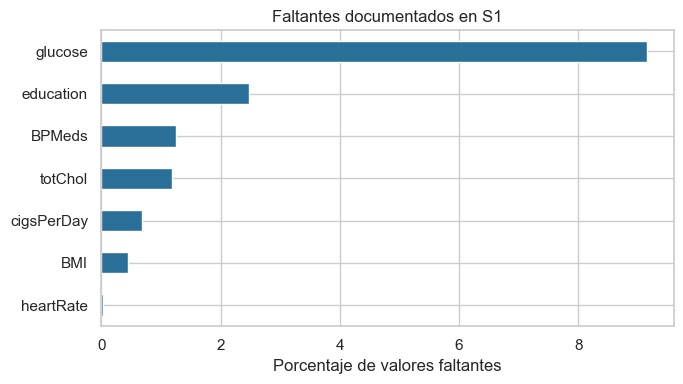

In [3]:
original = cargar_datos()
faltantes = resumen_faltantes(original)
faltantes.to_csv(TABLAS / 'p1_faltantes_s1.csv')
display(faltantes.round(3))
print(f'Filas con al menos un faltante: {original.isna().any(axis=1).sum()} ({100*original.isna().any(axis=1).mean():.1f} %)')

ax = faltantes.sort_values('porcentaje_faltantes')['porcentaje_faltantes'].plot.barh(
    figsize=(7, 4), color='#2A6F97'
)
ax.set(xlabel='Porcentaje de valores faltantes', ylabel='', title='Faltantes documentados en S1')
plt.tight_layout()
plt.savefig(FIGURAS / 'p1_fig1_faltantes.png', dpi=180)
plt.show()

## 1.2 Imputación mediante regresión lineal múltiple

`imputar_regresion()` está implementada en `utils_s3.py`. Para cada variable numérica incompleta se ajusta una regresión con observaciones completas y 3–5 predictores. Se priorizan las correlaciones estables de S2 y nunca se usa `TenYearCHD` como predictor de imputación. Las predicciones se restringen al rango observado y la mediana actúa únicamente como respaldo si una fila carece de predictores.

El desempeño se estima en una validación 80/20 dentro de los casos completos. Jarque–Bera, Breusch–Pagan, VIF y distancia de Cook permiten evaluar los supuestos; una imputación puede ser útil para preservar tamaño muestral aunque su R² sea modesto, pero esa limitación debe declararse.

In [4]:
regresion, estado_regresion, diagnosticos, conteos = imputar_regresion(
    original, devolver_detalle=True
)
diagnosticos.to_csv(TABLAS / 'p1_diagnosticos_imputacion.csv', index=False)
conteos.to_csv(TABLAS / 'p1_conteos_imputados.csv', index=False)
display(conteos.fillna('').style.format(precision=0))
display(diagnosticos.style.format({
    'R2_validacion': '{:.3f}', 'RMSE_validacion': '{:.3f}',
    'MAE_validacion': '{:.3f}', 'JB_p_residuos': '{:.3g}',
    'BP_p_heterocedasticidad': '{:.3g}', 'VIF_max': '{:.2f}',
    'Cook_max': '{:.3f}'
}))
assert regresion.isna().sum().sum() == 0

,variable,n_imputados,metodo,n_por_regresion,n_respaldo_mediana
0,education,105,moda,,
1,BPMeds,53,moda,,
2,cigsPerDay,29,regresion lineal multiple,29,0
3,totChol,50,regresion lineal multiple,50,0
4,BMI,19,regresion lineal multiple,19,0
5,heartRate,1,regresion lineal multiple,1,0
6,glucose,388,regresion lineal multiple,388,0


,variable,n_ajuste,predictores,R2_validacion,RMSE_validacion,MAE_validacion,JB_p_residuos,BP_p_heterocedasticidad,VIF_max,Cook_max
0,cigsPerDay,4211,"currentSmoker, age, male, sysBP, diaBP",0.619,7.490,4.662,0,1.68e-127,3.08,0.011
1,totChol,4190,"age, sysBP, diaBP, male, currentSmoker",0.105,42.778,33.436,0,0.00835,3.08,0.026
2,BMI,4221,"diaBP, sysBP, age, male, currentSmoker",0.148,3.569,2.746,4.63e-295,1.26e-45,3.11,0.034
3,heartRate,4239,"age, sysBP, diaBP, male, currentSmoker",0.088,11.477,8.973,1.22e-96,1.18e-06,3.10,0.016
4,glucose,3827,"age, diabetes, sysBP, diaBP, cigsPerDay",0.456,20.796,11.672,0,7.39e-243,3.06,0.283


La intensidad de tabaquismo presenta el mejor desempeño de imputación porque `currentSmoker` aporta información directa. Para colesterol, IMC, frecuencia cardiaca y glucosa el error es mayor; además, la normalidad y homocedasticidad pueden incumplirse por la asimetría clínica ya observada en S1/S2. Por ello los valores imputados no deben interpretarse como mediciones individuales exactas: su finalidad es conservar la estructura del conjunto para el modelamiento y se exige contrastar las conclusiones con eliminación e imputación simple.

## 1.3 Construcción y comparación de las tres estrategias

1. **Eliminación completa:** conserva solo filas sin faltantes.  
2. **Imputación simple:** mediana para numéricas y moda para categóricas.  
3. **Imputación por regresión:** regresiones múltiples para numéricas y moda para categóricas.

In [5]:
eliminacion = original.dropna().copy()
simple = imputar_simple(original)
datasets = {'eliminacion': eliminacion, 'simple': simple, 'regresion': regresion}

for nombre, df in datasets.items():
    df.to_csv(DATOS_SALIDA / f'framingham_{nombre}.csv', index=False)

tamanos = pd.DataFrame([
    {
        'estrategia': nombre, 'n': len(df),
        'filas_perdidas': len(original) - len(df),
        'eventos_CHD': int(df['TenYearCHD'].sum()),
        'tasa_CHD': df['TenYearCHD'].mean()
    }
    for nombre, df in datasets.items()
])
distribuciones = comparar_distribuciones(original, datasets)
correlaciones = comparar_correlaciones(datasets)
tamanos.to_csv(TABLAS / 'p1_comparacion_tamanos.csv', index=False)
distribuciones.to_csv(TABLAS / 'p1_comparacion_distribuciones.csv', index=False)
correlaciones.to_csv(TABLAS / 'p1_preservacion_correlaciones.csv', index=False)
display(tamanos.style.format({'tasa_CHD': '{:.3%}'}))
display(distribuciones.round(3))
display(correlaciones.round(4))

,estrategia,n,filas_perdidas,eventos_CHD,tasa_CHD
0,eliminacion,3658,582,557,15.227%
1,simple,4240,0,644,15.189%
2,regresion,4240,0,644,15.189%


,estrategia,variable,n,media,DE,mediana,IQR,media_original_disponible
0,eliminacion,cigsPerDay,3658,9.0250,11.9220,0.0000,20.0000,9.0060
1,eliminacion,totChol,3658,236.8480,44.0980,234.0000,57.0000,236.7000
2,eliminacion,BMI,3658,25.7830,4.0660,25.3800,4.9580,25.8010
3,eliminacion,heartRate,3658,75.7310,11.9820,75.0000,14.0000,75.8790
4,eliminacion,glucose,3658,81.8530,23.9040,78.0000,16.0000,81.9640
5,simple,cigsPerDay,4240,8.9440,11.9050,0.0000,20.0000,9.0060
6,simple,totChol,4240,236.6680,44.3280,234.0000,56.0000,236.7000
7,simple,BMI,4240,25.7990,4.0710,25.4000,4.9550,25.8010
8,simple,heartRate,4240,75.8790,12.0240,75.0000,15.0000,75.8790
9,simple,glucose,4240,81.6010,22.8600,78.0000,13.0000,81.9640


,estrategia,par,correlacion,diferencia_vs_regresion
0,eliminacion,sysBP - diaBP,0.7867,0.0027
1,eliminacion,age - sysBP,0.3883,-0.0058
2,eliminacion,BMI - diaBP,0.3853,0.0072
3,eliminacion,totChol - glucose,0.0499,0.0049
4,eliminacion,cigsPerDay - glucose,-0.0537,0.0024
5,simple,sysBP - diaBP,0.7840,0.0000
6,simple,age - sysBP,0.3941,0.0000
7,simple,BMI - diaBP,0.3764,-0.0018
8,simple,totChol - glucose,0.0457,0.0007
9,simple,cigsPerDay - glucose,-0.0568,-0.0007


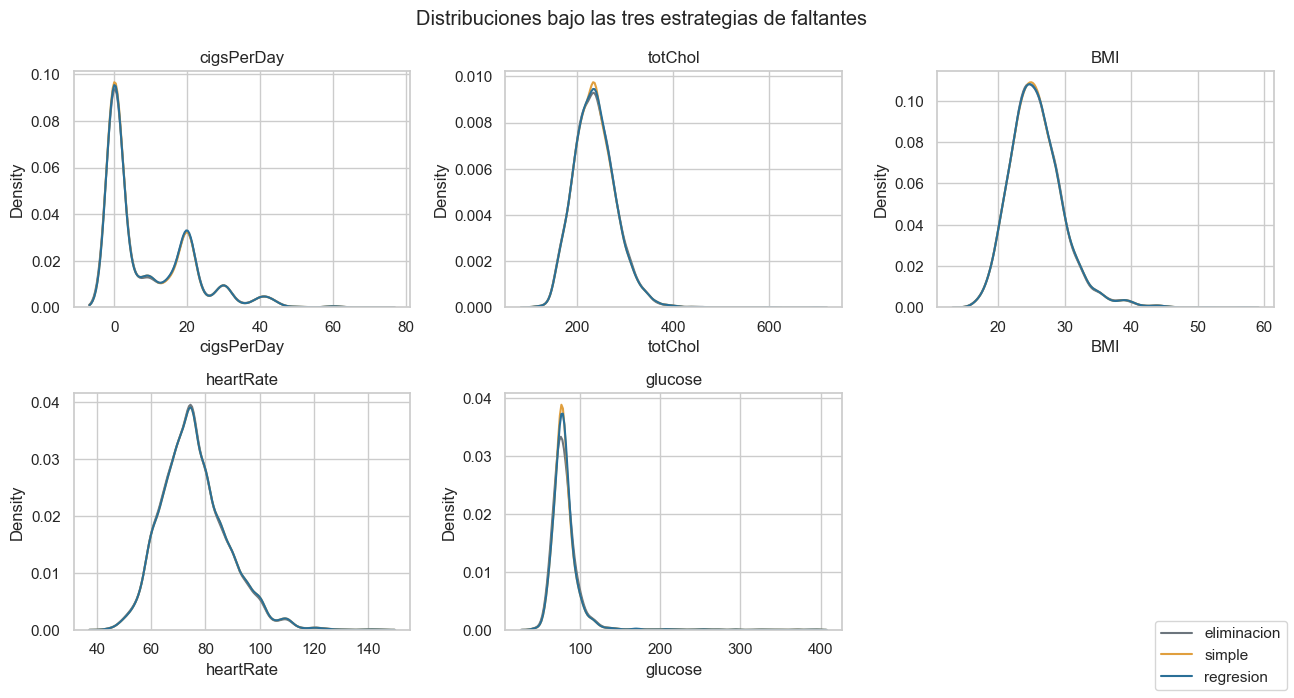

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
variables = ['cigsPerDay', 'totChol', 'BMI', 'heartRate', 'glucose']
colores = {'eliminacion': '#6C757D', 'simple': '#E09F3E', 'regresion': '#2A6F97'}
for ax, variable in zip(axes.ravel(), variables):
    for nombre, df in datasets.items():
        sns.kdeplot(df[variable], ax=ax, label=nombre, color=colores[nombre], warn_singular=False)
    ax.set_title(variable)
axes.ravel()[-1].axis('off')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower right')
fig.suptitle('Distribuciones bajo las tres estrategias de faltantes')
fig.tight_layout()
plt.savefig(FIGURAS / 'p1_fig2_distribuciones_imputacion.png', dpi=180, bbox_inches='tight')
plt.show()

## 1.4 Decisión para las fases posteriores

Se selecciona **imputación por regresión** como estrategia principal porque conserva los 4.240 participantes y usa relaciones multivariadas justificadas por S1/S2. La eliminación completa pierde 582 registros (13,7 %) y 87 eventos de CHD, lo que reduce información de la clase minoritaria. La imputación simple también conserva el tamaño, pero comprime artificialmente la variabilidad alrededor de medianas/modas.

La decisión no implica que la regresión reconstruya con precisión cada medición: los R² modestos y los incumplimientos de supuestos obligan a mantener la comparación de sensibilidad de la Parte 4. Los tres CSV quedan guardados en `S3/datos/` para que el trabajo grupal utilice exactamente las mismas versiones.

# Parte 2. Clasificación con regresión logística

En esta parte se construyen tres modelos de regresión logística para predecir la enfermedad coronaria a 10 años
(`TenYearCHD`): uno con las variables validadas en la S1 y la S2, uno con selección stepwise según AIC y el mejor
subconjunto según BIC entre todos los modelos posibles. Como solo el 15,2 % de las personas desarrolla CHD, los tres
se ajustan ponderando las clases. Se comparan en entrenamiento y prueba, se elige el modelo final y se revisan sus
supuestos. Todo parte del dataset con imputación por regresión que eligió la parte 1.

In [7]:
# la parte 1 reutiliza el nombre df: se vuelve a cargar y particionar
df = cargar_datos()
train, test = particionar(df)

In [8]:
def ajustar(variables, tr, te, ponderar=True, recortar=None):
    """Prepara las matrices y ajusta la regresión logística (ponderada por defecto)."""
    X_tr, X_te, y_tr, y_te = preparar_modelo(tr, te, variables, recortar=recortar)
    return ajustar_logit(X_tr, y_tr, ponderar=ponderar), X_tr, X_te, y_tr, y_te


def tabla_coeficientes(modelo):
    ic = modelo.conf_int()
    tabla = pd.DataFrame({
        "coef": modelo.params, "EE": modelo.bse, "p": modelo.pvalues,
        "OR": np.exp(modelo.params), "OR_IC95_inf": np.exp(ic[0]), "OR_IC95_sup": np.exp(ic[1]),
    }).drop(index="const")
    tabla.index.name = "variable"
    return tabla


def metricas(y, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "especificidad": tn / (tn + fp), "F1": f1_score(y, pred),
            "AUC": roc_auc_score(y, prob), "TN": tn, "FP": fp, "FN": fn, "TP": tp}

## 2.1 Preparación de los datos

**Imputación.** Se usa la imputación por regresión elegida en la parte 1. Como en esa parte, la partición 70/30
estratificada por `TenYearCHD` se hace antes de imputar y los modelos de imputación se ajustan solo con
entrenamiento.

In [9]:
ESTRATEGIA = "regresion"
tr, te = imputar(train, test, ESTRATEGIA)
resumen = pd.DataFrame({
    "n": [len(tr), len(te)],
    "casos CHD": [int(tr[OBJETIVO].sum()), int(te[OBJETIVO].sum())],
    "% CHD": [tr[OBJETIVO].mean() * 100, te[OBJETIVO].mean() * 100],
    "faltantes": [int(tr.isna().sum().sum()), int(te.isna().sum().sum())],
}, index=["entrenamiento", "prueba"])
resumen

,n,casos CHD,% CHD,faltantes
entrenamiento,2968,451,15.1954,0
prueba,1272,193,15.1730,0


**Ponderación de clases.** Con 15,2 % de casos, un modelo sin ponderar aprende sobre todo a reconocer a quienes
no desarrollan CHD. Siguiendo la sugerencia del profesor, cada observación recibe un peso n / (2 · n de su clase),
calculado en entrenamiento. Así las dos clases pesan lo mismo en la verosimilitud y los pesos suman n. Como los
pesos no son frecuencias, los errores estándar se calculan con la versión robusta (HC0).

In [10]:
pesos = pesos_clases(tr[OBJETIVO])
PESOS = {"casos": round(float(pesos[tr[OBJETIVO] == 1].iloc[0]), 4),
         "no_casos": round(float(pesos[tr[OBJETIVO] == 0].iloc[0]), 4)}
print(f"Peso de los casos: {PESOS['casos']:.2f} | peso de los no casos: {PESOS['no_casos']:.2f} | suma: {pesos.sum():.0f}")

Peso de los casos: 3.29 | peso de los no casos: 0.59 | suma: 2968


**Outliers.** La S1 encontró atípicos en el extremo superior de todas las variables clínicas y decidió
conservarlos por ser clínicamente posibles. La S2 mostró que las medias son robustas a ellos, salvo la glucosa,
cuya diferencia según CHD depende de sus valores extremos. Antes de decidir, se cuentan los atípicos de Tukey en
entrenamiento y se compara el modelo 1 (sección 2.2) con y sin recorte de las colas.

In [11]:
filas = []
for v in ["totChol", "sysBP", "BMI", "heartRate", "glucose", "cigsPerDay"]:
    q1, q3 = tr[v].quantile([0.25, 0.75])
    limite = q3 + 1.5 * (q3 - q1)
    filas.append({"variable": NOMBRES[v], "límite Tukey": limite, "n atípicos": int((tr[v] > limite).sum()),
                  "% atípicos": (tr[v] > limite).mean() * 100, "P99": tr[v].quantile(0.99), "máximo": tr[v].max()})
guardar_tabla(pd.DataFrame(filas).set_index("variable").round(2), "p2_outliers_entrenamiento")

,límite Tukey,n atípicos,% atípicos,P99,máximo
variable,,,,,
Colesterol total (mg/dL),346.0000,41,1.3800,355.9900,600.0000
Presión sistólica (mmHg),183.2500,91,3.0700,200.0000,295.0000
IMC (kg/m²),35.5900,71,2.3900,39.1800,56.8000
Frecuencia cardíaca (lpm),105.5000,51,1.7200,110.0000,143.0000
Glucosa (mg/dL),107.0000,146,4.9200,174.3200,394.0000
Cigarrillos por día,50.0000,5,0.1700,43.0000,70.0000


In [12]:
VARIABLES_S1_S2 = ["age", "male", "sysBP", "prevalentHyp", "cigsPerDay", "glucose"]
recortes = {
    "sin recorte (S1)": None,
    "glucosa y colesterol al P99": {"glucose": (0, 99), "totChol": (0, 99)},
    "todas las continuas al P0,5-P99,5": {v: (0.5, 99.5) for v in ["glucose", "totChol", "sysBP", "BMI", "heartRate", "cigsPerDay"]},
}
filas = []
for nombre, recorte in recortes.items():
    m, X_tr, X_te, y_tr, y_te = ajustar(VARIABLES_S1_S2, tr, te, recortar=recorte)
    fila = {"tratamiento": nombre, "AUC prueba": roc_auc_score(y_te, predecir(m, X_te))}
    fila.update({f"OR {v}": np.exp(m.params[v]) for v in VARIABLES_S1_S2})
    filas.append(fila)
guardar_tabla(pd.DataFrame(filas).set_index("tratamiento").round(3), "p2_sensibilidad_outliers")

,AUC prueba,OR age,OR male,OR sysBP,OR prevalentHyp,OR cigsPerDay,OR glucose
tratamiento,,,,,,,
sin recorte (S1),0.7080,1.9220,1.4860,1.3340,1.2780,1.3240,1.1850
glucosa y colesterol al P99,0.7060,1.9200,1.4870,1.3360,1.2780,1.3240,1.1590
"todas las continuas al P0,5-P99,5",0.7080,1.9270,1.4800,1.3360,1.2680,1.3310,1.1740


Recortar las colas casi no cambia el modelo: el AUC en prueba se mueve entre 0,706 y 0,708 y los odds ratios varían en
el segundo decimal. Por eso se conservan los outliers, igual que en la S1: son valores clínicamente posibles (por
ejemplo, glucosas altas en diabéticos) y recortarlos no mejora el ajuste. En la sección 2.7 se revisa si alguno
de ellos es influyente en el modelo final.

**Estandarización y codificación.** `preparar_modelo()` estandariza las variables continuas con la media y la DE
de entrenamiento, deja las binarias en 0/1 y codifica `education` con variables indicadoras (categoría de
referencia: nivel 1) cuando se incluye. Así, el odds ratio de una variable continua corresponde a un aumento de
una desviación estándar.

## 2.2 Modelo 1: variables validadas en la S1 y la S2

Las variables se eligen con la evidencia de las dos sumativas anteriores:

| Variable | Evidencia S1 | Evidencia S2 | Decisión |
| --- | --- | --- | --- |
| Edad | Mayor diferencia entre grupos (g = 0,64) | Media robusta; confusor del tabaquismo | Se incluye |
| Sexo masculino | Tasa de CHD 18,8 % en hombres vs 12,4 % en mujeres | Sin cambios | Se incluye |
| Presión sistólica | Diferencia de 13,28 mmHg (g = 0,62, p < 0,001) | IC BCa [11,14; 15,60]; validada por permutación | Se incluye |
| Hipertensión | Tasa de CHD 24,7 % vs 10,9 % | Entrada más influyente del Monte Carlo; había que estimarla ajustada | Se incluye junto a la sistólica (VIF de abajo) |
| Cigarrillos por día | Asociación marginal débil (g = 0,16), oculta por la edad | Al ajustar por edad el tabaquismo sí se asocia (p < 0,001) | Se incluye, ajustado por edad |
| Glucosa | Diferencia de 8,33 mg/dL (g = 0,35) | IC BCa [5,32; 12,16]; sensible a atípicos | Se incluye y se vigila |
| Presión diastólica | g = 0,41 | ρ = 0,78 con la sistólica, la más estable | Se excluye por colinealidad |
| Diabetes | Tasa de 36,7 %, pero n = 109 | Mediana de glucosa 145 vs 78 mg/dL | Se excluye: la glucosa ya la recoge (ver abajo) |
| Fumador actual | Sin asociación marginal (p = 0,221) | Información contenida en cigarrillos por día | Se excluye |
| Antihipertensivos, ACV previo | Tasas altas en grupos pequeños | Subgrupos con poca potencia (ACV n = 25) | Quedan como candidatas del stepwise |
| Colesterol, IMC, frecuencia cardíaca | Efectos pequeños (g ≤ 0,23) | Correlaciones débiles o inestables | Quedan como candidatas del stepwise |

**Multicolinealidad entre las candidatas.** Antes de ajustar se calcula el VIF con todas las candidatas a la vez,
con y sin la presión diastólica.

In [13]:
CANDIDATOS = ["age", "male", "education", "currentSmoker", "cigsPerDay", "BPMeds", "prevalentStroke",
              "prevalentHyp", "diabetes", "totChol", "sysBP", "BMI", "heartRate", "glucose"]


def vif(variables):
    X = sm.add_constant(preparar_modelo(tr, te, variables)[0], has_constant="add")
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=X.columns[1:])


vif_todas = pd.DataFrame({"con diastólica": vif(CANDIDATOS + ["diaBP"]), "sin diastólica": vif(CANDIDATOS),
                          "modelo 1": vif(VARIABLES_S1_S2)})
vif_todas.index = [NOMBRES.get(c, c.replace("edu_", "Nivel educativo ")) for c in vif_todas.index]
guardar_tabla(vif_todas.round(2), "p2_vif")

,con diastólica,sin diastólica,modelo 1
IMC (kg/m²),1.2400,1.2000,NaN
Antihipertensivos,1.0900,1.0900,NaN
Edad (años),1.4200,1.3700,1.2400
Cigarrillos por día,2.7300,2.7300,1.1600
Fumador actual,2.6000,2.5900,NaN
Presión diastólica (mmHg),2.9700,NaN,NaN
Diabetes,1.6700,1.6700,NaN
Nivel educativo 2.0,1.2700,1.2700,NaN
Nivel educativo 3.0,1.2100,1.2000,NaN
Nivel educativo 4.0,1.1700,1.1700,NaN


Con la diastólica incluida, la sistólica llega a un VIF de 3,78 y la diastólica a 2,97: las dos
presiones comparten información, como ya se vio en la S2. Al sacar la diastólica, la sistólica baja a 2,25
aunque estén la hipertensión y la diabetes en el modelo, y ningún VIF supera 3. Por eso se puede mantener la
hipertensión junto a la sistólica. En el modelo 1 todos los VIF quedan bajo 2,2.

In [14]:
m1, X1_tr, X1_te, y_tr, y_te = ajustar(VARIABLES_S1_S2, tr, te)
tabla_m1 = tabla_coeficientes(m1)
guardar_tabla(tabla_m1.round(4), "p2_modelo1_coeficientes")

,coef,EE,p,OR,OR_IC95_inf,OR_IC95_sup
variable,,,,,,
age,0.6534,0.0610,0.0000,1.9220,1.7054,2.1661
male,0.3960,0.1223,0.0012,1.4858,1.1692,1.8881
sysBP,0.2878,0.0749,0.0001,1.3335,1.1515,1.5444
prevalentHyp,0.2455,0.1572,0.1184,1.2782,0.9393,1.7395
cigsPerDay,0.2807,0.0579,0.0000,1.3240,1.1819,1.4833
glucose,0.1699,0.0468,0.0003,1.1851,1.0812,1.2991


In [15]:
# la diabetes no aporta una vez que está la glucosa
m1_dm = ajustar(VARIABLES_S1_S2 + ["diabetes"], tr, te)[0]
print(f"Diabetes agregada al modelo 1: OR = {np.exp(m1_dm.params['diabetes']):.2f}, p = {m1_dm.pvalues['diabetes']:.3f}")

Diabetes agregada al modelo 1: OR = 1.05, p = 0.904


In [16]:
# odds ratios en unidades clínicas: OR por Δ unidades = exp(β / DE × Δ)
de = tr[["age", "sysBP", "cigsPerDay", "glucose"]].std(ddof=0)
unidades = {"age": (10, "10 años"), "sysBP": (10, "10 mmHg"), "cigsPerDay": (10, "10 cigarrillos"), "glucose": (10, "10 mg/dL")}
ic = m1.conf_int()
clinicos = pd.DataFrame({
    "aumento": [unidades[v][1] for v in unidades],
    "OR": [np.exp(m1.params[v] / de[v] * unidades[v][0]) for v in unidades],
    "IC95_inf": [np.exp(ic.loc[v, 0] / de[v] * unidades[v][0]) for v in unidades],
    "IC95_sup": [np.exp(ic.loc[v, 1] / de[v] * unidades[v][0]) for v in unidades],
}, index=[NOMBRES[v] for v in unidades])
guardar_tabla(clinicos.round(3), "p2_modelo1_or_clinicos")

,aumento,OR,IC95_inf,IC95_sup
Edad (años),10 años,2.1360,1.8590,2.4540
Presión sistólica (mmHg),10 mmHg,1.1410,1.0670,1.2200
Cigarrillos por día,10 cigarrillos,1.2660,1.1510,1.3930
Glucosa (mg/dL),10 mg/dL,1.0740,1.0340,1.1170


Cinco de los seis predictores son significativos y todos aumentan el riesgo. Manteniendo constantes las demás
variables:

- Edad: cada 10 años la odds de CHD se multiplica por 2,14. Es el factor más fuerte, como en la S1.
- Sexo masculino: los hombres tienen una odds 1,49 veces la de las mujeres.
- Presión sistólica: cada 10 mmHg la odds aumenta un 14 % (OR = 1,14).
- Cigarrillos por día: cada 10 cigarrillos diarios la odds aumenta un 27 % (OR = 1,27). Esto confirma lo que
  mostró la S2: el tabaquismo sí importa cuando se controla por edad, aunque la comparación bivariada de la S1 no
  lo detectara.
- Glucosa: cada 10 mg/dL la odds aumenta un 7 % (OR = 1,07). Es el efecto más pequeño, coherente con su
  sensibilidad a atípicos en la S2.
- Hipertensión: OR de 1,28, pero con IC 95 % de 0,94 a 1,74 (p = 0,118). Gran parte de su efecto bivariado
  (24,7 % frente a 10,9 % en la S1) queda explicado por la presión sistólica y la edad. Se mantiene porque es un
  factor clínico relevante, porque el VIF muestra que no daña al resto del modelo y porque la S2 pedía estimarla
  ajustada. El bootstrap de la parte 3 permite ver si su signo es estable.

La diabetes no aporta nada una vez que está la glucosa (OR = 1,05, p = 0,904), así que se deja fuera.

## 2.3 Modelo 2: stepwise según AIC

Selección bidireccional: en cada paso se prueba agregar cada candidata que no está y quitar cada una de las que
están, y se hace el cambio que más baja el AIC. El proceso termina cuando ningún cambio lo baja. `education` entra
o sale como un solo término con sus tres indicadoras. Los candidatos son todos los predictores menos la presión
diastólica.

El AIC se calcula con la verosimilitud sin ponderar. Con los pesos la verosimilitud deja de ser la del modelo y la
penalización pierde su sentido: en una prueba, el stepwise ponderado retuvo 10 variables, varias sin efecto
significativo. Una vez elegidas las variables, el modelo se ajusta con ponderación como los demás.

In [17]:
def criterio(terminos, penalizacion):
    """AIC (penalización 2) o BIC (penalización ln n) con la verosimilitud sin ponderar."""
    if not terminos:
        y = tr[OBJETIVO]
        p = y.mean()
        return -2 * float((y * np.log(p) + (1 - y) * np.log(1 - p)).sum()) + penalizacion
    m = ajustar(terminos, tr, te, ponderar=False)[0]
    return -2 * m.llf + penalizacion * (int(m.df_model) + 1)


def stepwise(candidatos, penalizacion):
    seleccion, pasos = [], []
    actual = criterio(seleccion, penalizacion)
    while True:
        opciones = [(criterio(seleccion + [t], penalizacion), "entra", t) for t in candidatos if t not in seleccion]
        opciones += [(criterio([s for s in seleccion if s != t], penalizacion), "sale", t) for t in seleccion]
        valor, accion, t = min(opciones)
        if valor >= actual:
            return seleccion, pd.DataFrame(pasos).set_index("paso")
        seleccion = seleccion + [t] if accion == "entra" else [s for s in seleccion if s != t]
        actual = valor
        pasos.append({"paso": len(pasos) + 1, "acción": accion, "variable": t, "criterio": valor})


VARIABLES_AIC, pasos_aic = stepwise(CANDIDATOS, 2)
display(pasos_aic.round(1))
m2 = ajustar(VARIABLES_AIC, tr, te)[0]
guardar_tabla(tabla_coeficientes(m2).round(4), "p2_modelo2_coeficientes")

,acción,variable,criterio
paso,,,
1,entra,age,"2,357.5000"
2,entra,sysBP,"2,308.6000"
3,entra,cigsPerDay,"2,269.1000"
4,entra,glucose,"2,254.3000"
5,entra,male,"2,243.2000"
6,entra,prevalentStroke,"2,238.8000"
7,entra,totChol,"2,234.8000"
8,entra,BPMeds,"2,233.2000"


,coef,EE,p,OR,OR_IC95_inf,OR_IC95_sup
variable,,,,,,
age,0.6363,0.0618,0.0000,1.8895,1.6741,2.1327
sysBP,0.3238,0.0575,0.0000,1.3824,1.2351,1.5472
cigsPerDay,0.2805,0.0575,0.0000,1.3237,1.1826,1.4817
glucose,0.1690,0.0486,0.0005,1.1841,1.0765,1.3025
male,0.4322,0.1236,0.0005,1.5407,1.2092,1.9630
prevalentStroke,1.1814,0.4756,0.0130,3.2590,1.2832,8.2774
totChol,0.1305,0.0552,0.0181,1.1394,1.0226,1.2695
BPMeds,0.6826,0.2967,0.0214,1.9790,1.1064,3.5397


El stepwise agrega, en este orden, edad, presión sistólica, cigarrillos, glucosa, sexo, ACV previo, colesterol
total y antihipertensivos, y ninguna variable sale una vez que entra. La hipertensión no entra, porque con la
sistólica ya presente su aporte no compensa la penalización.

**Odds ratios del modelo 2.** Las cinco variables que comparte con el modelo 1 tienen efectos parecidos: edad 1,89
por DE, sexo masculino 1,54, cigarrillos 1,32 por DE y glucosa 1,18 por DE. La sistólica sube a 1,38 por DE porque
recoge el efecto que en el modelo 1 se reparte con la hipertensión. Las tres variables extra deben leerse con
cautela. El ACV previo tiene un OR de 3,26 con IC de 1,28 a 8,28: es grande, pero se apoya en solo 25 personas de
toda la muestra y su IC es muy ancho; la S2 advirtió que en subgrupos de ese tamaño la potencia es muy baja. Los
antihipertensivos (OR 1,98; IC 1,11 a 3,54) probablemente marcan hipertensión más severa y no un efecto del
tratamiento, y el colesterol aporta poco (1,14 por DE; IC 1,02 a 1,27).

## 2.4 Modelo 3: mejor subconjunto según BIC

El modelo 3 usa un criterio de información, no una regla de selección paso a paso: es el subconjunto de candidatos
con menor BIC entre todos los posibles. Hay 14 candidatos, así que son 16.383 modelos. El BIC penaliza ln n ≈ 8 por
parámetro en lugar de 2, de modo que solo entran variables con un aporte claro. La celda siguiente encuentra ese
modelo con una búsqueda paso a paso con penalización BIC, que es rápida; la búsqueda exhaustiva de más abajo
comprueba que es el mínimo global.

In [18]:
VARIABLES_BIC, pasos_bic = stepwise(CANDIDATOS, np.log(len(tr)))
display(pasos_bic.round(1))
m3 = ajustar(VARIABLES_BIC, tr, te)[0]
guardar_tabla(tabla_coeficientes(m3).round(4), "p2_modelo3_coeficientes")

,acción,variable,criterio
paso,,,
1,entra,age,"2,369.5000"
2,entra,sysBP,"2,326.6000"
3,entra,cigsPerDay,"2,293.0000"
4,entra,glucose,"2,284.2000"
5,entra,male,"2,279.2000"


,coef,EE,p,OR,OR_IC95_inf,OR_IC95_sup
variable,,,,,,
age,0.6589,0.0608,0.0000,1.9327,1.7157,2.1771
sysBP,0.3674,0.0558,0.0000,1.4439,1.2944,1.6107
cigsPerDay,0.2776,0.0577,0.0000,1.3200,1.1788,1.4781
glucose,0.1696,0.0473,0.0003,1.1848,1.0799,1.3000
male,0.3967,0.1220,0.0012,1.4868,1.1706,1.8886


Se ajustan todos los subconjuntos posibles de los 14 candidatos (16.383 modelos) y se buscan los de menor AIC y BIC.
Así se define el modelo 3 y se comprueba que el stepwise del modelo 2 no se quedó en un óptimo local. Tarda unos
dos minutos.

In [19]:
y_tr_bin = tr[OBJETIVO].astype(int)
resultados = []
for k in range(1, len(CANDIDATOS) + 1):
    for combinacion in itertools.combinations(CANDIDATOS, k):
        X = sm.add_constant(preparar_modelo(tr, te, list(combinacion))[0], has_constant="add")
        m = sm.Logit(y_tr_bin, X).fit(disp=False, maxiter=200)
        resultados.append({"variables": ", ".join(combinacion), "k": int(m.df_model), "AIC": m.aic, "BIC": m.bic})
busqueda = pd.DataFrame(resultados)
mejores_aic = busqueda.nsmallest(5, "AIC").reset_index(drop=True)
mejores_bic = busqueda.nsmallest(5, "BIC").reset_index(drop=True)
guardar_tabla(mejores_aic.round(1), "p2_mejores_aic")
guardar_tabla(mejores_bic.round(1), "p2_mejores_bic")
display(mejores_aic.round(1), mejores_bic.round(1))
print(f"Modelos ajustados: {len(busqueda)}")
print("¿El stepwise AIC llegó al mejor AIC?", set(mejores_aic.loc[0, "variables"].split(", ")) == set(VARIABLES_AIC))
print("¿El stepwise BIC llegó al mejor BIC?", set(mejores_bic.loc[0, "variables"].split(", ")) == set(VARIABLES_BIC))

,variables,k,AIC,BIC
0,"age, male, cigsPerDay, BPMeds, prevalentStroke...",8,"2,233.2000","2,287.2000"
1,"age, male, cigsPerDay, BPMeds, prevalentStroke...",9,"2,233.8000","2,293.7000"
2,"age, male, education, cigsPerDay, BPMeds, prev...",11,"2,234.2000","2,306.1000"
3,"age, male, cigsPerDay, BPMeds, prevalentStroke...",9,"2,234.4000","2,294.3000"
4,"age, male, education, cigsPerDay, BPMeds, prev...",12,"2,234.7000","2,312.7000"


,variables,k,AIC,BIC
0,"age, male, cigsPerDay, sysBP, glucose",5,"2,243.2000","2,279.2000"
1,"age, male, cigsPerDay, prevalentStroke, sysBP,...",6,"2,238.8000","2,280.7000"
2,"age, male, cigsPerDay, totChol, sysBP, glucose",6,"2,239.8000","2,281.7000"
3,"age, male, cigsPerDay, BPMeds, sysBP, glucose",6,"2,240.8000","2,282.7000"
4,"age, male, cigsPerDay, prevalentStroke, totCho...",7,"2,234.8000","2,282.8000"


Modelos ajustados: 16383
¿El stepwise AIC llegó al mejor AIC? True
¿El stepwise BIC llegó al mejor BIC? True


La búsqueda exhaustiva confirma los dos modelos. El stepwise según AIC llega al mejor subconjunto por AIC
(modelo 2), y el mejor subconjunto por BIC tiene edad, sexo, presión sistólica, cigarrillos y glucosa (BIC 2.279,2;
el siguiente, que agrega el ACV previo, tiene 2.280,7). Son las mismas variables del modelo 1, sin la hipertensión.
Es un resultado que respalda la selección hecha con la S1 y la S2, porque el criterio más estricto elige casi
exactamente esas variables sin conocerlas de antemano.

**Odds ratios del modelo 3.** Son casi iguales a los del modelo 1: edad 1,93 por DE (IC 1,72 a 2,18), sexo
masculino 1,49 (1,17 a 1,89), cigarrillos 1,32 por DE (1,18 a 1,48) y glucosa 1,18 por DE (1,08 a 1,30). Solo cambia
la sistólica, que sube de 1,33 a 1,44 por DE (1,29 a 1,61) al no estar la hipertensión. Es decir, los dos modelos
cuentan la misma historia: el efecto de la presión aparece en la sistólica, con o sin la etiqueta de hipertensión.

## 2.5 Desempeño de los tres modelos

Los tres modelos ponderados se evalúan con el umbral de 0,5 en entrenamiento y prueba. También se calcula el AUC
con validación cruzada de 5 particiones dentro de entrenamiento, y se agrega el modelo 1 sin ponderar como
referencia para ver qué cambia con la ponderación.

In [20]:
MODELOS = {"Modelo 1 (S1 y S2)": VARIABLES_S1_S2, "Modelo 2 (stepwise AIC)": VARIABLES_AIC, "Modelo 3 (reducido BIC)": VARIABLES_BIC}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

ajustes, filas_resumen, filas_metricas = {}, [], []
for nombre, variables in list(MODELOS.items()) + [("Modelo 1 sin ponderar", VARIABLES_S1_S2)]:
    ponderar = nombre != "Modelo 1 sin ponderar"
    m, X_tr, X_te, y_tr, y_te = ajustar(variables, tr, te, ponderar=ponderar)
    p_tr, p_te = predecir(m, X_tr), predecir(m, X_te)
    auc_cv = []
    for i_a, i_b in skf.split(tr, tr[OBJETIVO]):
        m_cv, _, X_b, _, y_b = ajustar(variables, tr.iloc[i_a], tr.iloc[i_b], ponderar=ponderar)
        auc_cv.append(roc_auc_score(y_b, predecir(m_cv, X_b)))
    ajustes[nombre] = {"modelo": m, "p_tr": p_tr, "p_te": p_te, "y_tr": y_tr, "y_te": y_te}
    filas_resumen.append({"modelo": nombre, "variables": len(variables),
                          "AUC entrenamiento": roc_auc_score(y_tr, p_tr), "AUC CV (media)": np.mean(auc_cv),
                          "AUC CV (DE)": np.std(auc_cv), "AUC prueba": roc_auc_score(y_te, p_te)})
    for conjunto, y, p in [("entrenamiento", y_tr, p_tr), ("prueba", y_te, p_te)]:
        filas_metricas.append({"modelo": nombre, "conjunto": conjunto, **metricas(y, p)})

resumen_modelos = guardar_tabla(pd.DataFrame(filas_resumen).set_index("modelo").round(3), "p2_resumen_modelos")
display(resumen_modelos)
tabla_metricas = guardar_tabla(pd.DataFrame(filas_metricas).set_index(["modelo", "conjunto"]).round(3), "p2_metricas_modelos")
tabla_metricas

,variables,AUC entrenamiento,AUC CV (media),AUC CV (DE),AUC prueba
modelo,,,,,
Modelo 1 (S1 y S2),6,0.7390,0.7370,0.0130,0.7080
Modelo 2 (stepwise AIC),8,0.7440,0.7420,0.0110,0.7000
Modelo 3 (reducido BIC),5,0.7380,0.7370,0.0120,0.7050
Modelo 1 sin ponderar,6,0.7390,0.7370,0.0130,0.7090


accuracy  precision  recall  \
modelo                  conjunto                                     
Modelo 1 (S1 y S2)      entrenamiento    0.6750     0.2740  0.6900   
                        prueba           0.6810     0.2670  0.6320   
Modelo 2 (stepwise AIC) entrenamiento    0.6780     0.2760  0.6900   
                        prueba           0.6710     0.2560  0.6170   
Modelo 3 (reducido BIC) entrenamiento    0.6730     0.2710  0.6830   
                        prueba           0.6780     0.2640  0.6270   
Modelo 1 sin ponderar   entrenamiento    0.8550     0.7080  0.0750   
                        prueba           0.8470     0.4800  0.0620   

                                       especificidad     F1    AUC    TN   FP  \
modelo                  conjunto                                                
Modelo 1 (S1 y S2)      entrenamiento         0.6730 0.3920 0.7390  1693  824   
                        prueba                0.6900 0.3750 0.7080   744  335   
Modelo 2 (stepwise AIC) entrenamiento         0.6760 0.3940 0.7440  1701  816   
                        prueba                0.6800 0.3620 0.7000   734  345   
Modelo 3 (reducido BIC) entrenamiento         0.6710 0.3880 0.7380  1690  827   
                        prueba                0.6870 0.3710 0.7050   741  338   
Modelo 1 sin ponderar   entrenamiento         0.9940 0.1360 0.7390  2503   14   
                        prueba                0.9880 0.1100 0.7090  1066   13   

                                        FN   TP  
modelo                  conjunto                 
Modelo 1 (S1 y S2)      entrenamiento  140  311  
                        prueba          71  122  
Modelo 2 (stepwise AIC) entrenamiento  140  311  
                        prueba          74  119  
Modelo 3 (reducido BIC) entrenamiento  143  308  
                        prueba          72  121  
Modelo 1 sin ponderar   entrenamiento  417   34  
                        prueba         181   12

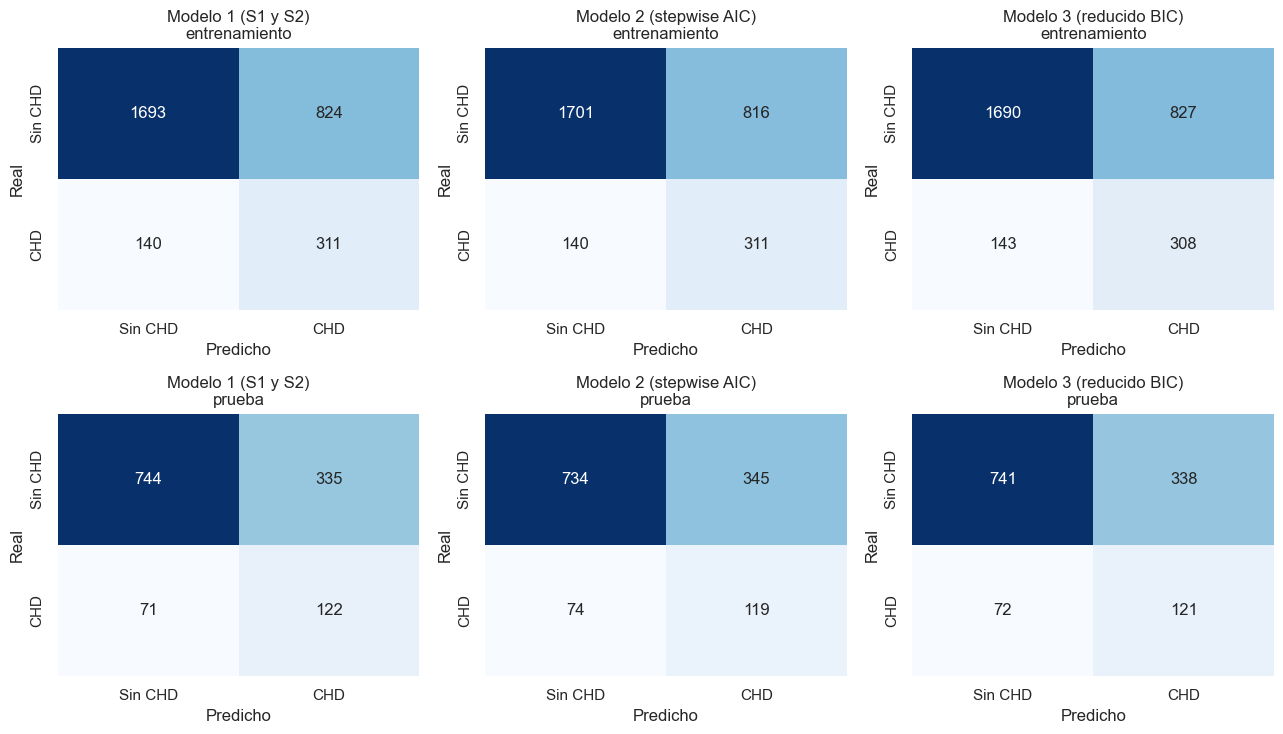

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for j, nombre in enumerate(MODELOS):
    a = ajustes[nombre]
    for i, (conjunto, y, p) in enumerate([("entrenamiento", a["y_tr"], a["p_tr"]), ("prueba", a["y_te"], a["p_te"])]):
        cm = confusion_matrix(y, (p >= 0.5).astype(int), labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Blues", ax=axes[i, j],
                    xticklabels=["Sin CHD", "CHD"], yticklabels=["Sin CHD", "CHD"])
        axes[i, j].set(title=f"{nombre}\n{conjunto}", xlabel="Predicho", ylabel="Real")
guardar_figura("p2_fig1_matrices_confusion")

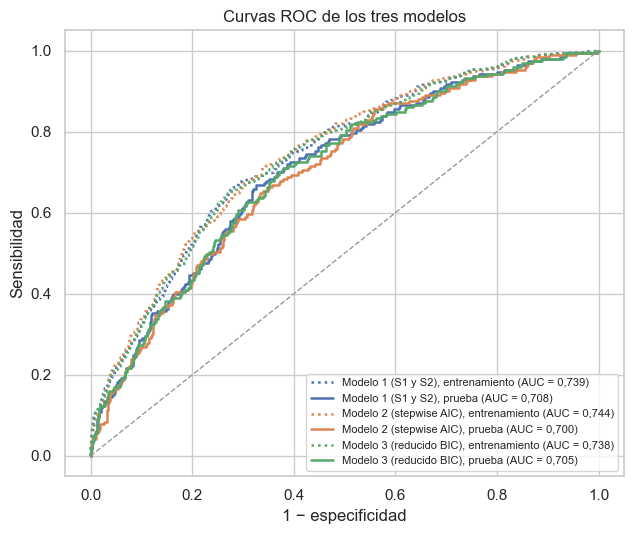

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
colores = ["#4C72B0", "#DD8452", "#55A868"]
for color, nombre in zip(colores, MODELOS):
    a = ajustes[nombre]
    for conjunto, y, p, estilo in [("entrenamiento", a["y_tr"], a["p_tr"], ":"), ("prueba", a["y_te"], a["p_te"], "-")]:
        fpr, tpr, _ = roc_curve(y, p)
        ax.plot(fpr, tpr, estilo, color=color, lw=1.8,
                label=f"{nombre}, {conjunto} (AUC = {roc_auc_score(y, p):.3f})".replace(".", ","))
ax.plot([0, 1], [0, 1], color="0.6", lw=1, ls="--")
ax.set(xlabel="1 − especificidad", ylabel="Sensibilidad", title="Curvas ROC de los tres modelos")
ax.legend(fontsize=8, loc="lower right")
guardar_figura("p2_fig2_curvas_roc")

La ponderación cambia por completo la lectura de las métricas. Sin ponderar, el modelo 1 tiene una accuracy de
0,847 en prueba, pero solo porque casi todo se clasifica como "sin CHD": detecta 12 de los 193 casos (recall de
6 %). Ponderado, con el mismo umbral de 0,5, detecta 122 de los 193 (recall de 63 %) y el F1 sube de 0,11 a 0,38.
El costo son más falsos positivos (precision de 0,27) y una accuracy menor (0,68). El AUC casi no cambia (0,709
frente a 0,708), porque la ponderación mueve sobre todo el intercepto y no el orden de las personas según su
riesgo. En prevención, dejar pasar a una persona que desarrollará CHD es más costoso que citar a control a una
persona sana, así que el modelo ponderado es el adecuado.

Los tres modelos discriminan de forma parecida, en el rango aceptable (AUC de 0,7 a 0,8 según Hosmer et al.,
2013). En validación cruzada los modelos 1 y 3 empatan (0,737) y el modelo 2 queda apenas arriba (0,742). En prueba
el orden se invierte: el modelo 2 tiene el AUC más bajo (0,700) y el peor recall (0,617), señal de que sus tres
variables extra se ajustan a particularidades del entrenamiento. Los modelos 1 y 3 son casi iguales (AUC 0,708
frente a 0,705 y recall 0,632 frente a 0,627). Estas diferencias de AUC son menores que la incertidumbre del propio
AUC: en la parte 3, el IC bootstrap del AUC del modelo 1 en prueba es [0,669; 0,745] y contiene a los tres.

## 2.6 Modelo final

Se elige el modelo 1 (edad, sexo, presión sistólica, hipertensión, cigarrillos por día y glucosa, con
ponderación de clases). El AUC no sirve para decidir, porque la validación cruzada empata a los modelos 1 y 3 y
las diferencias en prueba caben en el IC bootstrap del AUC. La elección se apoya en tres argumentos:

1. **Parsimonia y respaldo de la S1 y la S2.** Tiene 6 variables, todas elegidas con evidencia previa, y el
   criterio más estricto (BIC) elige las mismas sin la hipertensión. El modelo 2 agrega variables con efectos
   pequeños o basadas en subgrupos muy chicos, como el ACV previo (n = 25), y es el que más empeora en prueba.
2. **Recall.** Es el que más casos detecta en prueba (recall 0,632 frente a 0,627 y 0,617; F1 0,375), que es la
   métrica que la S2 pidió priorizar para la clase minoritaria.
3. **Uso práctico.** Edad, sexo, presión, hipertensión, tabaquismo y glucosa se miden en un control de rutina. La
   hipertensión se mantiene por su relevancia clínica y porque no daña al resto (VIF bajo 2,2); el modelo 3 queda
   como la alternativa más simple, con un AUC casi igual.

Los datos de prueba solo confirman la elección. El modelo final se guarda en `config_modelo_final.json`, junto con
los pesos de clase, para que lo usen las partes 3 (bootstrap) y 4 (impacto de la imputación). Para ajustarlo igual
que aquí basta con `ajustar_logit()` de `utils_s3.py`.

In [23]:
VARIABLES_FINAL = VARIABLES_S1_S2
config = {"variables": VARIABLES_FINAL, "estrategia_imputacion": ESTRATEGIA, "recorte_outliers": None,
          "ponderacion": {"metodo": "n / (2 · n_clase), calculado en entrenamiento", **PESOS},
          "umbral": 0.5, "ajuste": "utils_s3.ajustar_logit(X, y, ponderar=True)", "fuente": "02_modelos_logisticos.ipynb"}
(S3 / "config_modelo_final.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
config

{'variables': ['age',
  'male',
  'sysBP',
  'prevalentHyp',
  'cigsPerDay',
  'glucose'],
 'estrategia_imputacion': 'regresion',
 'recorte_outliers': None,
 'ponderacion': {'metodo': 'n / (2 · n_clase), calculado en entrenamiento',
  'casos': 3.2905,
  'no_casos': 0.5896},
 'umbral': 0.5,
 'ajuste': 'utils_s3.ajustar_logit(X, y, ponderar=True)',
 'fuente': '02_modelos_logisticos.ipynb'}

## 2.7 Diagnóstico del modelo final

**Multicolinealidad (VIF).** Ya se revisó en la sección 2.2: en el modelo final todos los VIF están entre 1,03 y 2,13. El más alto es el de la sistólica, por su relación con la hipertensión, y sigue lejos de 5.

**Linealidad en el logit.** Se usa la prueba de Box-Tidwell: a cada variable continua x se le agrega el término
x·ln(x) y se revisa si es significativo (a cigarrillos se le suma 1 para evitar ln(0)). También se grafica el logit
empírico por deciles de cada variable.

In [24]:
continuas = ["age", "sysBP", "cigsPerDay", "glucose"]
bt = tr[VARIABLES_FINAL].astype(float).copy()
bt["cigsPerDay"] = bt["cigsPerDay"] + 1
for v in continuas:
    bt[f"{v}_xlnx"] = bt[v] * np.log(bt[v])
m_bt = ajustar_logit(bt, tr[OBJETIVO].astype(int))
box_tidwell = pd.DataFrame({"coef x·ln(x)": [m_bt.params[f"{v}_xlnx"] for v in continuas],
                            "p": [m_bt.pvalues[f"{v}_xlnx"] for v in continuas]},
                           index=[NOMBRES[v] for v in continuas])
guardar_tabla(box_tidwell.round(4), "p2_box_tidwell")

,coef x·ln(x),p
Edad (años),-0.2286,0.0080
Presión sistólica (mmHg),0.0266,0.2674
Cigarrillos por día,-0.0044,0.6901
Glucosa (mg/dL),0.0080,0.2932


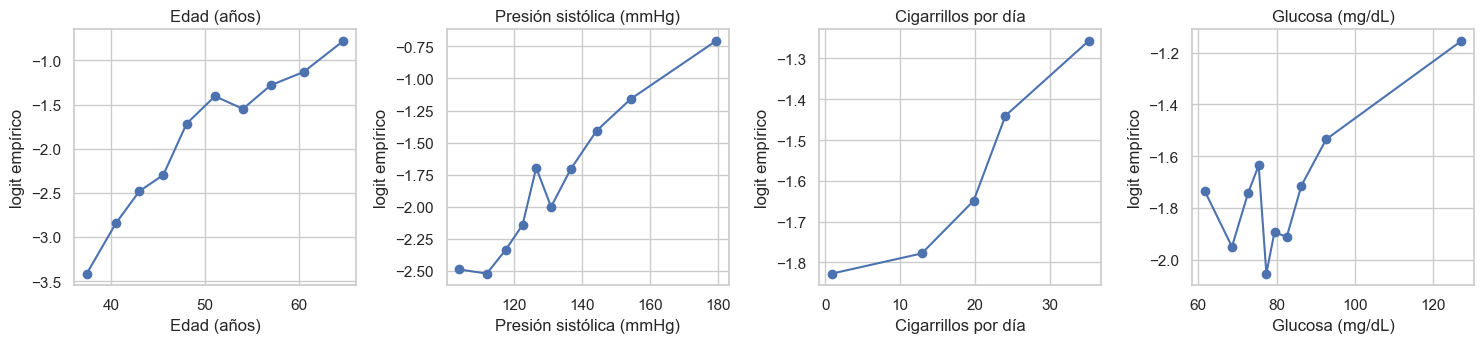

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, v in zip(axes, continuas):
    grupos = tr.groupby(pd.qcut(tr[v], 10, duplicates="drop"), observed=True)
    tasa = grupos[OBJETIVO].mean().clip(0.005, 0.995)
    ax.plot(grupos[v].mean(), np.log(tasa / (1 - tasa)), "o-", color="#4C72B0")
    ax.set(xlabel=NOMBRES[v], ylabel="logit empírico", title=NOMBRES[v])
guardar_figura("p2_fig3_logit_empirico")

In [26]:
# sensibilidad: término cuadrático para la edad
m1_age2 = ajustar_logit(X1_tr.assign(age2=X1_tr["age"] ** 2), y_tr)
pd.DataFrame({"AUC prueba": [roc_auc_score(y_te, predecir(m1, X1_te)),
                             roc_auc_score(y_te, predecir(m1_age2, X1_te.assign(age2=X1_te["age"] ** 2)))],
              "p edad²": [np.nan, m1_age2.pvalues["age2"]]},
             index=["modelo 1", "modelo 1 + edad²"]).round(4)

,AUC prueba,p edad²
modelo 1,0.7082,NaN
modelo 1 + edad²,0.7045,0.0115


La presión sistólica, los cigarrillos y la glucosa cumplen el supuesto (p de Box-Tidwell entre 0,27 y 0,69). La
edad muestra una desviación leve (p = 0,008): en el gráfico, el riesgo crece algo más lento en las edades altas.
Al agregar un término cuadrático el AUC en prueba baja de 0,708 a 0,705, así que se mantiene la edad lineal y se
deja la no linealidad como mejora posible.

**Observaciones influyentes.** Se calculan la distancia de Cook y el leverage del modelo ponderado.

In [27]:
glm = sm.GLM(y_tr, sm.add_constant(X1_tr), family=sm.families.Binomial(), var_weights=pesos_clases(y_tr).values).fit()
influencia = glm.get_influence()
cook, leverage = influencia.cooks_distance[0], influencia.hat_matrix_diag
print(f"Distancia de Cook máxima: {cook.max():.4f} | observaciones con Cook > 0,5: {(cook > 0.5).sum()}")
print(f"Leverage máximo: {leverage.max():.4f} (2p/n = {2 * (X1_tr.shape[1] + 1) / len(y_tr):.4f})")
top = np.argsort(cook)[-5:][::-1]
display(tr.iloc[top][VARIABLES_FINAL + [OBJETIVO]].assign(Cook=cook[top].round(4)))

filas = []
for k in [5, 10, 20]:
    mantener = np.ones(len(y_tr), dtype=bool)
    mantener[np.argsort(cook)[-k:]] = False
    m_k = ajustar_logit(X1_tr[mantener], y_tr[mantener])
    cambio = (np.exp(m_k.params) / np.exp(m1.params) - 1) * 100
    filas.append({"sin las k más influyentes": k, **{f"Δ% OR {v}": cambio[v] for v in VARIABLES_FINAL},
                  "AUC prueba": roc_auc_score(y_te, predecir(m_k, X1_te))})
guardar_tabla(pd.DataFrame(filas).set_index("sin las k más influyentes").round(2), "p2_sensibilidad_influyentes")

Distancia de Cook máxima: 0.0262 | observaciones con Cook > 0,5: 0
Leverage máximo: 0.0807 (2p/n = 0.0047)


,age,male,sysBP,prevalentHyp,cigsPerDay,glucose,TenYearCHD,Cook
3487,35,0,83.5000,0,20.0000,63.0000,1,0.0262
1649,43,0,155.5000,1,0.0000,274.0000,1,0.0227
247,40,0,114.0000,0,20.0000,169.9589,1,0.0223
868,40,0,104.0000,0,30.0000,62.0000,1,0.0146
97,40,0,100.0000,0,0.0000,72.0000,1,0.0145


,Δ% OR age,Δ% OR male,Δ% OR sysBP,Δ% OR prevalentHyp,Δ% OR cigsPerDay,Δ% OR glucose,AUC prueba
sin las k más influyentes,,,,,,,
5,2.9300,5.8000,3.5900,-3.4500,-1.0300,-2.2700,0.7100
10,7.7700,3.8700,4.0600,-1.8500,1.9700,-2.4700,0.7100
20,13.2400,1.8400,6.2800,-6.5600,4.8200,-0.7300,0.7100


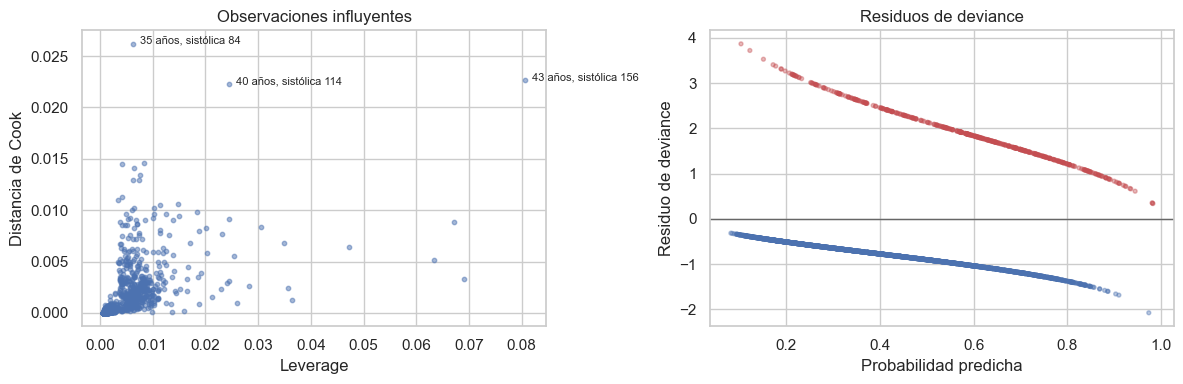

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(leverage, cook, s=10, alpha=0.5, color="#4C72B0")
for i in top[:3]:
    axes[0].annotate(f"{tr.iloc[i]['age']:.0f} años, sistólica {tr.iloc[i]['sysBP']:.0f}", (leverage[i], cook[i]), fontsize=8,
                     xytext=(5, 0), textcoords="offset points")
axes[0].set(xlabel="Leverage", ylabel="Distancia de Cook", title="Observaciones influyentes")
residuos = glm.resid_deviance
axes[1].scatter(glm.fittedvalues, residuos, s=8, alpha=0.4, c=np.where(y_tr == 1, "#C44E52", "#4C72B0"))
axes[1].axhline(0, color="0.4", lw=1)
axes[1].set(xlabel="Probabilidad predicha", ylabel="Residuo de deviance", title="Residuos de deviance")
guardar_figura("p2_fig4_influencia_residuos")

Ninguna observación tiene una distancia de Cook preocupante: el máximo es 0,026, muy lejos de 0,5. Las más
influyentes son casos de CHD poco esperables, como mujeres jóvenes con presión normal, que pesan más por la
ponderación. Al quitar las 5, 10 o 20 observaciones más influyentes, el AUC en prueba se mantiene en 0,710 y los
odds ratios cambian menos de 7 %, salvo el de la edad, que sube hasta 13 % al quitar 20. La dirección de todos los
efectos se mantiene, así que el modelo no depende de unas pocas personas.

En los residuos de deviance se ven las dos bandas típicas de una respuesta binaria. Los casos tienen residuos más
grandes porque cada uno pesa 3,29.

**Calibración.** La ponderación mueve las probabilidades hacia arriba a propósito, para que el umbral de 0,5 separe
mejor los casos. Por eso sus probabilidades no son riesgos reales. Se compara la calibración por deciles del
modelo ponderado con la del mismo modelo sin ponderar, y se aplica la prueba de Hosmer-Lemeshow a este último.

Hosmer-Lemeshow sin ponderar, entrenamiento: χ² = 15.54, gl = 8, p = 0.049
Hosmer-Lemeshow sin ponderar, prueba: χ² = 10.21, gl = 8, p = 0.250
Riesgo medio predicho: ponderado 0.439 | sin ponderar 0.152 | observado 0.152


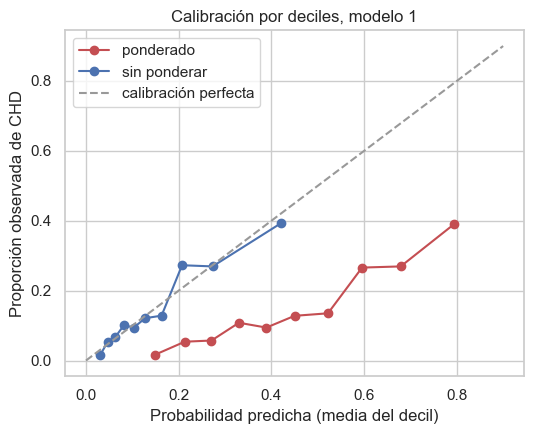

In [29]:
def calibracion(y, p):
    t = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    t["decil"] = pd.qcut(t["p"], 10, labels=False)
    return t.groupby("decil").agg(observados=("y", "sum"), esperados=("p", "sum"), n=("y", "size"), p_media=("p", "mean"))


cal_pond = calibracion(y_tr, ajustes["Modelo 1 (S1 y S2)"]["p_tr"])
cal_sin = calibracion(y_tr, ajustes["Modelo 1 sin ponderar"]["p_tr"])


def hosmer_lemeshow(cal):
    hl = (((cal["observados"] - cal["esperados"]) ** 2) / (cal["esperados"] * (1 - cal["esperados"] / cal["n"]))).sum()
    return hl, stats.chi2.sf(hl, 8)


for conjunto, y, p in [("entrenamiento", y_tr, ajustes["Modelo 1 sin ponderar"]["p_tr"]),
                       ("prueba", y_te, ajustes["Modelo 1 sin ponderar"]["p_te"])]:
    hl, p_hl = hosmer_lemeshow(calibracion(y, p))
    print(f"Hosmer-Lemeshow sin ponderar, {conjunto}: χ² = {hl:.2f}, gl = 8, p = {p_hl:.3f}")
print(f"Riesgo medio predicho: ponderado {cal_pond['esperados'].sum() / len(y_tr):.3f} | "
      f"sin ponderar {cal_sin['esperados'].sum() / len(y_tr):.3f} | observado {y_tr.mean():.3f}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for cal, color, etiqueta in [(cal_pond, "#C44E52", "ponderado"), (cal_sin, "#4C72B0", "sin ponderar")]:
    ax.plot(cal["p_media"], cal["observados"] / cal["n"], "o-", color=color, label=etiqueta)
ax.plot([0, 0.9], [0, 0.9], "--", color="0.6", label="calibración perfecta")
ax.set(xlabel="Probabilidad predicha (media del decil)", ylabel="Proporción observada de CHD",
       title="Calibración por deciles, modelo 1")
ax.legend()
guardar_figura("p2_fig5_calibracion")

Como se esperaba, el modelo ponderado sobreestima el riesgo en todos los deciles: predice un riesgo medio de 44 %
cuando el observado es 15 %. Para comunicar riesgos individuales se usa el mismo modelo sin ponderar, que sí está
calibrado en promedio (15,2 % predicho y observado). Su Hosmer-Lemeshow en entrenamiento queda justo en el límite
(p = 0,049), por diferencias en los deciles 7 y 8, pero en prueba no rechaza el buen ajuste (p = 0,25). Las dos
versiones ordenan igual a las personas: el modelo ponderado sirve para decidir a quién citar y el sin ponderar
para informar el riesgo.

## 2.8 Resumen de la parte 2

- Se usó la imputación por regresión, la partición 70/30 estratificada y pesos de 3,29 para los casos y 0,59
  para los no casos.
- Con todas las candidatas y sin la diastólica, el VIF de la sistólica es 2,25, así que la hipertensión se puede
  mantener junto a ella.
- El stepwise según AIC elige 8 variables (modelo 2) y el mejor subconjunto según BIC, 5 (modelo 3); la búsqueda
  exhaustiva de 16.383 modelos confirma ambos. La CV empata a los modelos 1 y 3 (AUC 0,737).
- El modelo final es el modelo 1: edad, sexo, presión sistólica, hipertensión, cigarrillos y glucosa. En prueba
  tiene AUC 0,708 y recall 0,632, frente a un recall de 0,062 sin ponderar.
- La hipertensión no es significativa una vez ajustada (p = 0,118). El bootstrap de la parte 3 muestra que ni su
  signo es seguro (6 % de las remuestras con signo opuesto).
- No hay multicolinealidad ni observaciones que cambien el modelo. La edad tiene una leve no linealidad que se
  puede abordar con splines como mejora futura.

# Parte 3. Estabilidad del modelo con bootstrap

En esta parte se mide qué tan estables son los coeficientes del modelo final elegido en la parte 2. Se remuestrean
las filas de entrenamiento 10.000 veces, se reajusta el modelo en cada remuestra y se construyen IC bootstrap al
95 % (percentil y BCa) para los coeficientes y los odds ratios. Se comparan con los IC tradicionales de Wald y se
identifican los parámetros inestables.

Es la misma técnica de la S2 (`S2/01_bootstrap_ic.ipynb`), que validó con bootstrap los IC clásicos de la S1: B =
10.000, semilla 42 e IC percentil frente a BCa con aceleración por jackknife. La diferencia es que ahora el
estadístico no es una media sino el vector de coeficientes de un modelo multivariado.

Todo se lee de `config_modelo_final.json`, que escribe la parte 2: variables, estrategia de imputación, recorte y
ponderación. Así el bootstrap usa exactamente el modelo final.

In [30]:
df = cargar_datos()
train, test = particionar(df)

## 3.0 Modelo final de la parte 2

Se carga la configuración, se imputa con la estrategia elegida (ajustada solo en entrenamiento), se preparan las
matrices con `preparar_modelo()` y se ajusta el modelo con `ajustar_logit()`. Antes de remuestrear se comprueba que
los coeficientes son los mismos de la parte 2.

In [31]:
config = json.loads((S3 / "config_modelo_final.json").read_text(encoding="utf-8"))
VARIABLES = config["variables"]
tr, te = imputar(train, test, config["estrategia_imputacion"])
X_tr, X_te, y_tr, y_te = preparar_modelo(tr, te, VARIABLES, recortar=config["recorte_outliers"])
modelo = ajustar_logit(X_tr, y_tr, ponderar=True)

referencia = pd.read_csv(TAB / "p2_modelo1_coeficientes.csv", index_col="variable")
assert np.allclose(modelo.params[VARIABLES].round(4), referencia.loc[VARIABLES, "coef"], atol=1e-4)
assert np.allclose(np.exp(modelo.conf_int().loc[VARIABLES]).round(4),
                   referencia.loc[VARIABLES, ["OR_IC95_inf", "OR_IC95_sup"]], atol=1e-4)
print("OK: coeficientes e IC iguales a los de la parte 2")
print(f"Variables: {', '.join(VARIABLES)} | imputación: {config['estrategia_imputacion']} | n = {len(y_tr)}")
modelo.params.round(4).to_frame("coef")

OK: coeficientes e IC iguales a los de la parte 2
Variables: age, male, sysBP, prevalentHyp, cigsPerDay, glucose | imputación: regresion | n = 2968


,coef
const,-0.5239
age,0.6534
male,0.3960
sysBP,0.2878
prevalentHyp,0.2455
cigsPerDay,0.2807
glucose,0.1699


## 3.1 Bootstrap de los coeficientes

Se remuestrean con reemplazo las 2.968 filas de entrenamiento. En cada remuestra se reajusta el mismo modelo:
mismas variables, misma escala (la estandarización de entrenamiento) y pesos de clase recalculados con la
remuestra, porque `pesos_clases()` los obtiene de `y`. En el bucle se usa `robusto=False`, que da los mismos
coeficientes y es más rápido. La imputación queda fija: el bootstrap mide la variabilidad del modelo, no la de la
imputación, que se revisa en la parte 4.

In [32]:
rng = np.random.default_rng(SEED)
n = len(y_tr)
X_arr, y_arr = X_tr.reset_index(drop=True), y_tr.reset_index(drop=True)
coefs = np.full((B, len(modelo.params)), np.nan)
no_convergen = 0
inicio = time.time()
for b in range(B):
    idx = rng.integers(0, n, n)
    try:
        m_b = ajustar_logit(X_arr.iloc[idx], y_arr.iloc[idx], ponderar=True, robusto=False)
        if m_b.converged:
            coefs[b] = m_b.params.values
        else:
            no_convergen += 1
    except Exception:
        no_convergen += 1
coefs = pd.DataFrame(coefs, columns=modelo.params.index).dropna()
print(f"Remuestras: {B:,} | válidas: {len(coefs):,} | no convergen: {no_convergen} | "
      f"tiempo: {time.time() - inicio:.0f} s")

Remuestras: 10,000 | válidas: 10,000 | no convergen: 0 | tiempo: 51 s


Para el IC BCa la aceleración se estima con jackknife: se reajusta el modelo quitando una fila a la vez (2.968
ajustes), igual que en la S2.

In [33]:
jack = np.empty((n, len(modelo.params)))
for i in range(n):
    mantener = np.arange(n) != i
    jack[i] = ajustar_logit(X_arr[mantener], y_arr[mantener], ponderar=True, robusto=False).params.values
jack = pd.DataFrame(jack, columns=modelo.params.index)


def intervalo_bca(distribucion, estimacion, jackknife, alpha=ALPHA):
    """IC BCa de Efron a partir de una distribución y valores jackknife (igual que en la S2)."""
    proporcion = (np.sum(distribucion < estimacion) + .5 * np.sum(distribucion == estimacion)) / len(distribucion)
    proporcion = np.clip(proporcion, 1 / (2 * len(distribucion)), 1 - 1 / (2 * len(distribucion)))
    z0 = stats.norm.ppf(proporcion)
    diferencias = jackknife.mean() - jackknife
    aceleracion = np.sum(diferencias ** 3) / (6 * np.sum(diferencias ** 2) ** 1.5)
    z = stats.norm.ppf([alpha / 2, 1 - alpha / 2])
    probabilidades = stats.norm.cdf(z0 + (z0 + z) / (1 - aceleracion * (z0 + z)))
    return np.quantile(distribucion, probabilidades)

## 3.2 Distribuciones bootstrap

Un panel por coeficiente con la estimación, el IC de Wald (EE robustos, como en la parte 2) y los IC percentil y
BCa. La línea gris marca el cero: si la distribución lo cruza, el signo del efecto no es seguro.

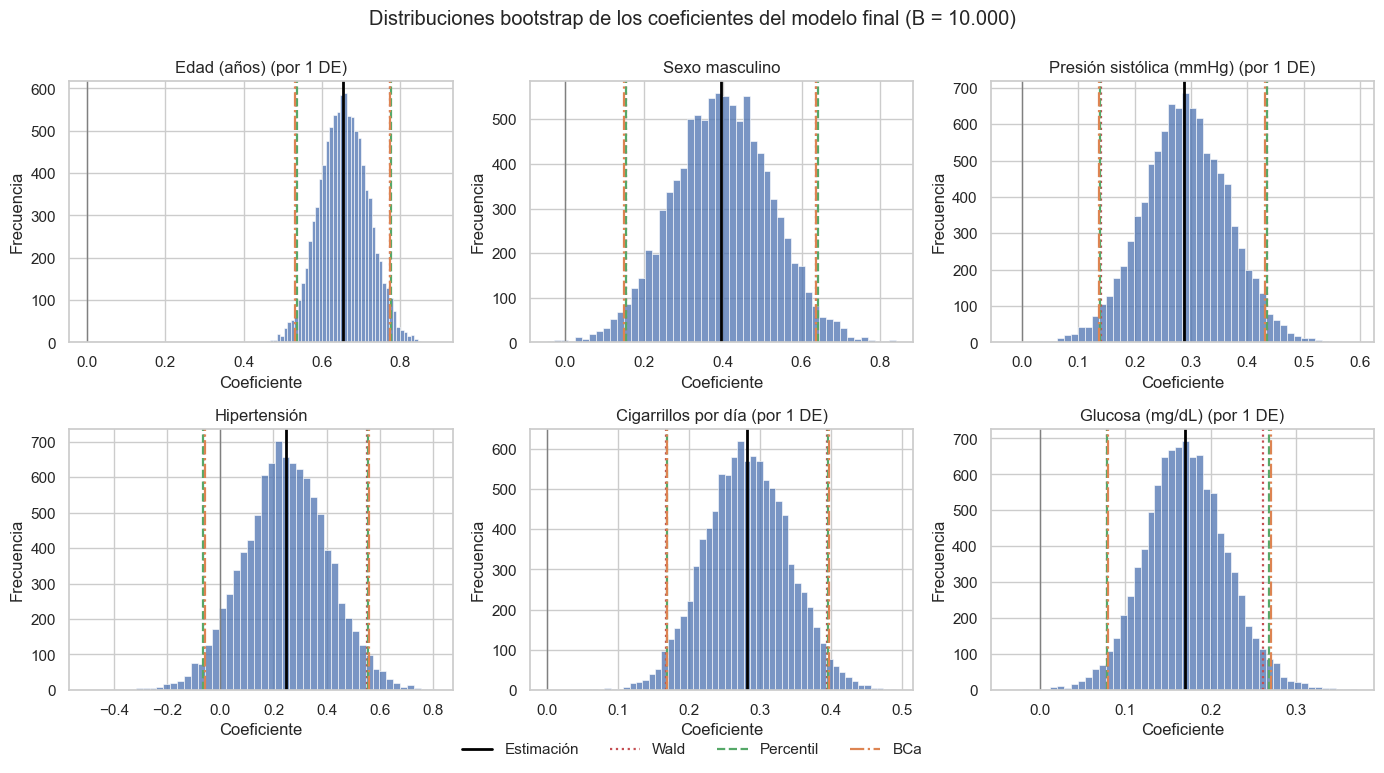

In [34]:
wald = modelo.conf_int()
ic_perc = coefs.quantile([ALPHA / 2, 1 - ALPHA / 2]).T
ic_bca = pd.DataFrame({v: intervalo_bca(coefs[v].values, modelo.params[v], jack[v].values) for v in coefs},
                      index=[0, 1]).T

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, v in zip(axes.flat, VARIABLES):
    sns.histplot(coefs[v], bins=50, color=COLORES["principal"], alpha=.75, ax=ax)
    ax.axvline(modelo.params[v], color="black", lw=2, label="Estimación")
    for ic, color, estilo, etiqueta in [(wald, COLORES["riesgo"], ":", "Wald"),
                                         (ic_perc, COLORES["ic"], "--", "Percentil"),
                                         (ic_bca, "#DD8452", "-.", "BCa")]:
        ax.axvline(ic.loc[v, ic.columns[0]], color=color, lw=1.6, ls=estilo, label=etiqueta)
        ax.axvline(ic.loc[v, ic.columns[1]], color=color, lw=1.6, ls=estilo)
    ax.axvline(0, color="0.5", lw=1)
    ax.set(title=NOMBRES[v] + (" (por 1 DE)" if v in NUMERICAS else ""), xlabel="Coeficiente", ylabel="Frecuencia")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
plt.suptitle(f"Distribuciones bootstrap de los coeficientes del modelo final (B = {len(coefs):,})".replace(",", "."), y=.995)
plt.tight_layout(rect=[0, .04, 1, .97])
guardar_figura("p3_fig1_distribuciones_bootstrap")

## 3.3 IC bootstrap y tradicionales

La tabla reúne, para cada coeficiente, la estimación, el odds ratio y sus IC al 95 % de Wald, percentil y BCa. Los
IC de los odds ratios son la exponencial de los extremos. En las variables continuas el odds ratio corresponde a un
aumento de 1 DE.

Los criterios se fijaron antes de mirar los resultados y se aplican tal cual. Un parámetro es **inestable** si
cumple al menos uno:

- (a) su IC bootstrap (percentil o BCa) incluye el 0;
- (b) cambia de signo en 2,5 % o más de las remuestras (equivale a que una cola del IC 95 % cruce el 0);
- (c) la razón de anchos IC percentil / IC Wald queda fuera de [0,8; 1,25].

Además se marca si el bootstrap y Wald **discrepan** (uno incluye el 0 y el otro no). "No significativo" e
"inestable" no son lo mismo: el primero se refiere al p de Wald; el segundo, a que la conclusión (el signo o el
ancho del IC) cambia con la muestra. La tabla indica qué criterio se cumple en cada caso.

Los criterios (a) y (b) son casi redundantes: un 2,5 % de remuestras con signo opuesto es justo lo que hace que una
cola del IC percentil 95 % toque el 0. Por eso un coeficiente no significativo tiende a cumplir los dos a la vez. Se
mantiene (b) porque cuantifica qué tan seguido se invierte el signo, y eso es lo que permite hablar de una
dirección incierta y no solo de falta de significación.

In [35]:
signo = np.sign(modelo.params[VARIABLES])
tabla = pd.DataFrame({
    "coef": modelo.params[VARIABLES],
    "EE_robusto": modelo.bse[VARIABLES],
    "EE_bootstrap": coefs[VARIABLES].std(),
    "sesgo_bootstrap": coefs[VARIABLES].mean() - modelo.params[VARIABLES],
    "p_Wald": modelo.pvalues[VARIABLES],
    "Wald_inf": wald.loc[VARIABLES, 0], "Wald_sup": wald.loc[VARIABLES, 1],
    "perc_inf": ic_perc.loc[VARIABLES].iloc[:, 0], "perc_sup": ic_perc.loc[VARIABLES].iloc[:, 1],
    "BCa_inf": ic_bca.loc[VARIABLES, 0], "BCa_sup": ic_bca.loc[VARIABLES, 1],
})
tabla.insert(5, "OR", np.exp(tabla["coef"]))
for metodo in ["Wald", "perc", "BCa"]:
    tabla[f"OR_{metodo}_inf"] = np.exp(tabla[f"{metodo}_inf"])
    tabla[f"OR_{metodo}_sup"] = np.exp(tabla[f"{metodo}_sup"])
tabla["%_signo_opuesto"] = [(np.sign(coefs[v]) != signo[v]).mean() * 100 for v in VARIABLES]
tabla["razon_anchos"] = (tabla["perc_sup"] - tabla["perc_inf"]) / (tabla["Wald_sup"] - tabla["Wald_inf"])

incluye_0 = lambda metodo: (tabla[f"{metodo}_inf"] < 0) & (tabla[f"{metodo}_sup"] > 0)
criterios = pd.DataFrame({
    "a": incluye_0("perc") | incluye_0("BCa"),
    "b": tabla["%_signo_opuesto"] >= 2.5,
    "c": ~tabla["razon_anchos"].between(0.8, 1.25),
})
tabla["discrepa_Wald_boot"] = incluye_0("Wald") != (incluye_0("perc") | incluye_0("BCa"))
tabla["criterios"] = criterios.apply(lambda f: ", ".join(f.index[f]) or "ninguno", axis=1)
tabla["clasificacion"] = np.where(~criterios.any(axis=1), "estable",
                                  np.where(tabla["p_Wald"] >= ALPHA, "inestable (no significativo)", "inestable"))
tabla.insert(0, "escala_OR", ["1 DE" if v in NUMERICAS else "sí vs no" for v in VARIABLES])
tabla.index = [NOMBRES[v] for v in VARIABLES]
tabla.index.name = "variable"
guardar_tabla(tabla.round(4), "p3_estabilidad_bootstrap")

,escala_OR,coef,EE_robusto,EE_bootstrap,sesgo_bootstrap,p_Wald,OR,Wald_inf,Wald_sup,perc_inf,...,OR_Wald_sup,OR_perc_inf,OR_perc_sup,OR_BCa_inf,OR_BCa_sup,%_signo_opuesto,razon_anchos,discrepa_Wald_boot,criterios,clasificacion
variable,,,,,,,,,,,,,,,,,,,,,
Edad (años),1 DE,0.6534,0.0610,0.0617,0.0027,0.0000,1.9220,0.5338,0.7729,0.5367,...,2.1661,1.7103,2.1759,1.7015,2.1660,0.0000,1.0070,False,ninguno,estable
Sexo masculino,sí vs no,0.3960,0.1223,0.1249,0.0022,0.0012,1.4858,0.1564,0.6356,0.1540,...,1.8881,1.1665,1.9004,1.1609,1.8904,0.0800,1.0185,False,ninguno,estable
Presión sistólica (mmHg),1 DE,0.2878,0.0749,0.0759,0.0014,0.0001,1.3335,0.1410,0.4346,0.1383,...,1.5444,1.1483,1.5461,1.1455,1.5406,0.0100,1.0132,False,ninguno,estable
Hipertensión,sí vs no,0.2455,0.1572,0.1582,0.0004,0.1184,1.2782,-0.0626,0.5536,-0.0639,...,1.7395,0.9381,1.7447,0.9422,1.7495,6.0400,1.0069,False,"a, b",inestable (no significativo)
Cigarrillos por día,1 DE,0.2807,0.0579,0.0587,0.0001,0.0000,1.3240,0.1671,0.3942,0.1679,...,1.4833,1.1828,1.4848,1.1835,1.4863,0.0000,1.0013,False,ninguno,estable
Glucosa (mg/dL),1 DE,0.1699,0.0468,0.0483,0.0011,0.0003,1.1851,0.0781,0.2617,0.0785,...,1.2991,1.0817,1.3079,1.0833,1.3109,0.0500,1.0345,False,ninguno,estable


In [36]:
# vista compacta para el informe y la presentación
compacta = pd.DataFrame({
    "OR": tabla["OR"].round(2),
    "IC Wald": [f"[{a:.2f}; {b:.2f}]" for a, b in zip(tabla["OR_Wald_inf"], tabla["OR_Wald_sup"])],
    "IC percentil": [f"[{a:.2f}; {b:.2f}]" for a, b in zip(tabla["OR_perc_inf"], tabla["OR_perc_sup"])],
    "IC BCa": [f"[{a:.2f}; {b:.2f}]" for a, b in zip(tabla["OR_BCa_inf"], tabla["OR_BCa_sup"])],
    "% signo opuesto": tabla["%_signo_opuesto"].round(2),
    "razón de anchos": tabla["razon_anchos"].round(2),
    "criterios": tabla["criterios"],
    "clasificación": tabla["clasificacion"],
})
compacta

,OR,IC Wald,IC percentil,IC BCa,% signo opuesto,razón de anchos,criterios,clasificación
variable,,,,,,,,
Edad (años),1.9200,[1.71; 2.17],[1.71; 2.18],[1.70; 2.17],0.0000,1.0100,ninguno,estable
Sexo masculino,1.4900,[1.17; 1.89],[1.17; 1.90],[1.16; 1.89],0.0800,1.0200,ninguno,estable
Presión sistólica (mmHg),1.3300,[1.15; 1.54],[1.15; 1.55],[1.15; 1.54],0.0100,1.0100,ninguno,estable
Hipertensión,1.2800,[0.94; 1.74],[0.94; 1.74],[0.94; 1.75],6.0400,1.0100,"a, b",inestable (no significativo)
Cigarrillos por día,1.3200,[1.18; 1.48],[1.18; 1.48],[1.18; 1.49],0.0000,1.0000,ninguno,estable
Glucosa (mg/dL),1.1900,[1.08; 1.30],[1.08; 1.31],[1.08; 1.31],0.0500,1.0300,ninguno,estable


Los odds ratios por 1 DE son difíciles de leer en consulta. Con las mismas remuestras se pasan a unidades clínicas
(OR por Δ unidades = exp(β / DE × Δ), con la DE de entrenamiento), igual que en la tabla `p2_modelo1_or_clinicos`.

In [37]:
de = tr[["age", "sysBP", "cigsPerDay", "glucose"]].std(ddof=0)
unidades = {"age": "10 años", "sysBP": "10 mmHg", "cigsPerDay": "10 cigarrillos", "glucose": "10 mg/dL"}
clinicos = pd.DataFrame({
    "aumento": list(unidades.values()),
    "OR": [np.exp(modelo.params[v] / de[v] * 10) for v in unidades],
    "Wald_inf": [np.exp(wald.loc[v, 0] / de[v] * 10) for v in unidades],
    "Wald_sup": [np.exp(wald.loc[v, 1] / de[v] * 10) for v in unidades],
    "perc_inf": [np.exp(coefs[v].quantile(ALPHA / 2) / de[v] * 10) for v in unidades],
    "perc_sup": [np.exp(coefs[v].quantile(1 - ALPHA / 2) / de[v] * 10) for v in unidades],
}, index=[NOMBRES[v] for v in unidades])
guardar_tabla(clinicos.round(3), "p3_or_clinicos_bootstrap")

,aumento,OR,Wald_inf,Wald_sup,perc_inf,perc_sup
Edad (años),10 años,2.1360,1.8590,2.4540,1.8650,2.4670
Presión sistólica (mmHg),10 mmHg,1.1410,1.0670,1.2200,1.0650,1.2210
Cigarrillos por día,10 cigarrillos,1.2660,1.1510,1.3930,1.1510,1.3940
Glucosa (mg/dL),10 mg/dL,1.0740,1.0340,1.1170,1.0340,1.1200


## 3.4 Comparación gráfica: Wald frente a bootstrap

El forest plot muestra los odds ratios con los tres IC en escala logarítmica. La línea vertical en 1 indica
ausencia de efecto.

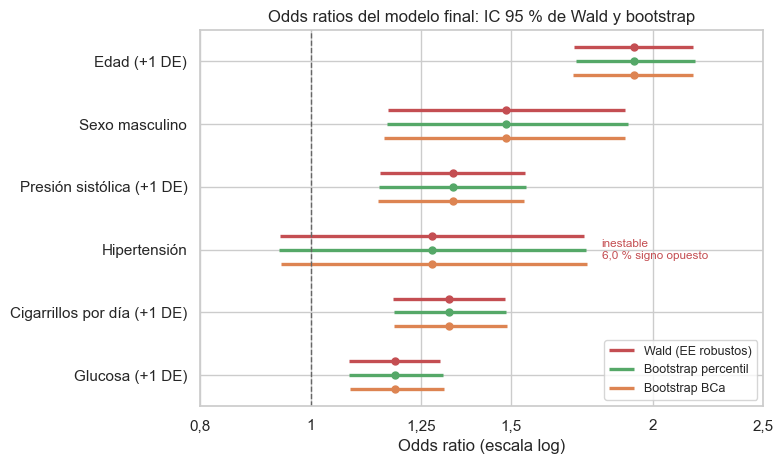

In [38]:
fig, ax = plt.subplots(figsize=(8, 4.8))
posiciones = np.arange(len(VARIABLES))[::-1]
for desplazamiento, (inf, sup, color, etiqueta) in zip([0.22, 0, -0.22], [
        ("OR_Wald_inf", "OR_Wald_sup", COLORES["riesgo"], "Wald (EE robustos)"),
        ("OR_perc_inf", "OR_perc_sup", COLORES["ic"], "Bootstrap percentil"),
        ("OR_BCa_inf", "OR_BCa_sup", "#DD8452", "Bootstrap BCa")]):
    y = posiciones + desplazamiento
    ax.hlines(y, tabla[inf], tabla[sup], color=color, lw=2.4, label=etiqueta)
    ax.plot(tabla["OR"], y, "o", color=color, ms=5)
ax.axvline(1, color="0.4", lw=1, ls="--")
ax.set_xscale("log")
ticks = [0.8, 1, 1.25, 1.5, 2, 2.5]
ax.set_xticks(ticks, [str(t).replace(".", ",") for t in ticks])
ETIQUETAS = {"age": "Edad (+1 DE)", "male": "Sexo masculino", "sysBP": "Presión sistólica (+1 DE)",
             "prevalentHyp": "Hipertensión", "cigsPerDay": "Cigarrillos por día (+1 DE)", "glucose": "Glucosa (+1 DE)"}
ax.set_yticks(posiciones, [ETIQUETAS.get(v, NOMBRES[v]) for v in VARIABLES])
for p, (i, fila) in zip(posiciones, tabla.iterrows()):
    if fila["clasificacion"] != "estable":
        texto = f"inestable\n{fila['%_signo_opuesto']:.1f} % signo opuesto".replace(".", ",")
        ax.text(fila["OR_BCa_sup"] * 1.03, p, texto, va="center", fontsize=8.5, color=COLORES["riesgo"])
ax.set(xlabel="Odds ratio (escala log)", title="Odds ratios del modelo final: IC 95 % de Wald y bootstrap")
ax.legend(loc="lower right", fontsize=9)
guardar_figura("p3_fig2_forest_or")

## 3.5 Extra: incertidumbre del AUC y del recall en prueba

El modelo final se mantiene fijo y se remuestrean las 1.272 filas de prueba 10.000 veces. Así se obtienen IC para
el AUC (0,708) y el recall (0,632), y se puede juzgar si las diferencias de AUC entre los tres modelos de la parte 2
(0,700 a 0,708) son relevantes.

In [39]:
rng_auc = np.random.default_rng(SEED)
p_te = np.asarray(predecir(modelo, X_te))
y_te_arr = y_te.to_numpy()
pred_te = (p_te >= config["umbral"]).astype(int)
auc_obs = roc_auc_score(y_te_arr, p_te)
recall_obs = pred_te[y_te_arr == 1].mean()
aucs, recalls = np.empty(B), np.empty(B)
for b in range(B):
    idx = rng_auc.integers(0, len(y_te_arr), len(y_te_arr))
    aucs[b] = roc_auc_score(y_te_arr[idx], p_te[idx])
    recalls[b] = pred_te[idx][y_te_arr[idx] == 1].mean()
auc_tabla = pd.DataFrame({
    "estimacion": [auc_obs, recall_obs], "EE_bootstrap": [aucs.std(), recalls.std()],
    "perc_inf": [np.quantile(aucs, ALPHA / 2), np.quantile(recalls, ALPHA / 2)],
    "perc_sup": [np.quantile(aucs, 1 - ALPHA / 2), np.quantile(recalls, 1 - ALPHA / 2)],
}, index=["AUC prueba", "recall prueba"])
guardar_tabla(auc_tabla.round(3), "p3_metricas_bootstrap")

,estimacion,EE_bootstrap,perc_inf,perc_sup
AUC prueba,0.7080,0.0200,0.6690,0.7450
recall prueba,0.6320,0.0350,0.5620,0.7010


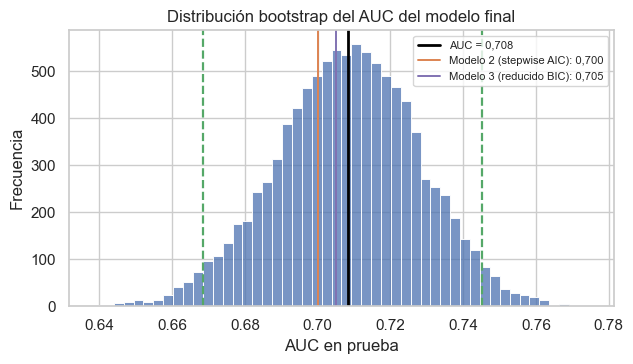

In [40]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.histplot(aucs, bins=50, color=COLORES["principal"], alpha=.75, ax=ax)
ax.axvline(auc_obs, color="black", lw=2, label=f"AUC = {auc_obs:.3f}".replace(".", ","))
for q in auc_tabla.loc["AUC prueba", ["perc_inf", "perc_sup"]]:
    ax.axvline(q, color=COLORES["ic"], lw=1.6, ls="--")
resumen_p2 = pd.read_csv(TAB / "p2_resumen_modelos.csv", index_col="modelo")["AUC prueba"]
for nombre, color in zip(["Modelo 2 (stepwise AIC)", "Modelo 3 (reducido BIC)"], ["#DD8452", "#8172B2"]):
    ax.axvline(resumen_p2[nombre], color=color, lw=1.4, label=f"{nombre}: {resumen_p2[nombre]:.3f}".replace(".", ","))
ax.set(xlabel="AUC en prueba", ylabel="Frecuencia", title="Distribución bootstrap del AUC del modelo final")
ax.legend(fontsize=8)
guardar_figura("p3_fig3_auc_bootstrap")

## 3.6 Resultados e implicancias

**Convergencia.** Las 10.000 remuestras convergieron; ninguna se descartó. El bucle tarda alrededor de un minuto.

**Cinco coeficientes estables.** Edad, sexo masculino, presión sistólica, cigarrillos por día y glucosa no
cumplen ningún criterio de inestabilidad. Sus IC bootstrap excluyen el 0, cambian de signo en a lo más 0,08 % de
las remuestras y tienen el mismo ancho que los de Wald (razón entre 1,00 y 1,03). El sesgo bootstrap es menor que
0,003 en todos.

| Variable | OR | IC Wald | IC percentil | IC BCa | % signo opuesto |
| --- | --- | --- | --- | --- | --- |
| Edad (+1 DE) | 1,92 | [1,71; 2,17] | [1,71; 2,18] | [1,70; 2,17] | 0,00 |
| Sexo masculino | 1,49 | [1,17; 1,89] | [1,17; 1,90] | [1,16; 1,89] | 0,08 |
| Presión sistólica (+1 DE) | 1,33 | [1,15; 1,54] | [1,15; 1,55] | [1,15; 1,54] | 0,01 |
| Hipertensión | 1,28 | [0,94; 1,74] | [0,94; 1,74] | [0,94; 1,75] | 6,04 |
| Cigarrillos por día (+1 DE) | 1,32 | [1,18; 1,48] | [1,18; 1,48] | [1,18; 1,49] | 0,00 |
| Glucosa (+1 DE) | 1,19 | [1,08; 1,30] | [1,08; 1,31] | [1,08; 1,31] | 0,05 |

En unidades clínicas, cada 10 años de edad multiplican la odds de CHD por 2,14 (IC bootstrap [1,87; 2,47]), cada
10 cigarrillos diarios por 1,27 ([1,15; 1,39]), cada 10 mmHg de sistólica por 1,14 ([1,07; 1,22]) y cada 10 mg/dL
de glucosa por 1,07 ([1,03; 1,12]).

**Un parámetro inestable, de dirección incierta: hipertensión.** Cumple los criterios (a) y (b), que como se
dijo van juntos: sus IC percentil y BCa incluyen el 0
(OR de 0,94 a 1,75) y el coeficiente tiene signo opuesto en 6,0 % de las remuestras. Ya era no significativa con
Wald (p = 0,118), así que el bootstrap no contradice a Wald: lo que agrega es que **la dirección** del efecto no
es segura, no solo su significación. Su efecto bivariado de la S1 (24,7 % de CHD con hipertensión frente a 10,9 %
sin ella) queda absorbido por la presión sistólica y la edad cuando se ajusta por ellas. Ninguna variable
discrepa entre Wald y bootstrap.

**Por qué Wald y bootstrap coinciden.** Los IC de Wald de la parte 2 ya usan errores estándar robustos (HC0,
sandwich), que son la aproximación asintótica de la varianza que estima el bootstrap de filas. Con 2.968
observaciones y 6 predictores, además, la distribución de cada coeficiente es casi normal (histogramas de la
sección 3.2), y los EE bootstrap difieren de los robustos en menos de 0,003. Que coincidan no significa que el
bootstrap no aporte: confirma sin suponer normalidad que los IC de la parte 2 son confiables, mide el sesgo (casi
nulo) y cuantifica cuántas veces cambia el signo, que es lo que permite separar "no significativo" de
"inestable". La distribución de la glucosa es levemente asimétrica: su IC bootstrap llega a un OR de 1,31 frente a
1,30 con Wald. La diferencia es mínima y no cambia ninguna conclusión.

**AUC y recall en prueba.** El AUC de 0,708 tiene IC bootstrap [0,669; 0,745] y el recall de 0,632, [0,562;
0,701]. Los AUC de los modelos 2 (0,700) y 3 (0,705) caen dentro de ese intervalo: la diferencia de AUC entre los
tres modelos no basta para elegir. La elección del modelo 1 se apoya en la parsimonia, el respaldo de la S1 y la
S2 y el recall (parte 2).

**Conexión con la S1 y la S2.**

- Edad y presión sistólica, las dos mayores diferencias de la S1 (g = 0,64 y 0,62) y validadas por bootstrap en la
  S2, son los efectos más estables.
- Los cigarrillos por día son estables una vez ajustados por edad, como anticipó la S2 (Mantel-Haenszel p < 0,001)
  pese a la asociación bivariada débil de la S1 (g = 0,16).
- La glucosa es estable en el modelo aunque en la S2 su diferencia entre grupos bajaba 90 % sin atípicos. En el
  modelo multivariado su efecto es pequeño (1,07 por 10 mg/dL) pero de signo seguro (0,05 % de signo opuesto).
- La hipertensión es la única inestable, en línea con la recomendación de la S2 de evaluarla ajustada por edad.

**Implicancias para la decisión.**

- Se pueden comunicar con confianza los efectos de edad, sexo, presión sistólica, tabaquismo y glucosa: su
  dirección y su magnitud no dependen de la muestra.
- La hipertensión debe comunicarse con cautela: no se puede afirmar un efecto independiente de la sistólica. El
  mensaje práctico es controlar la presión sistólica, cuyo efecto sí es estable. Se mantiene en el modelo por su
  relevancia clínica y porque no daña al resto (VIF bajo 2,2); el modelo 3 (BIC), que la excluye, es la
  alternativa más simple con un AUC casi igual (0,705).
- El bootstrap mantiene fija la imputación por regresión: mide la variabilidad del modelo, no la de la
  imputación, que se revisa en la parte 4.

La parte 4 usa el modelo final que define `config_modelo_final.json`: mismas variables, misma estandarización y el
mismo ajuste ponderado con errores estándar robustos de la parte 2.

# Sumativa 3 — Parte 4: impacto de la estrategia de imputación

Esta sección ajusta **el modelo logístico final de la Parte 2** bajo eliminación, imputación simple e imputación por regresión. Se comparan tamaño muestral, coeficientes, intervalos de confianza, AUC, accuracy y recall en prueba. No selecciona variables ni reemplaza el trabajo de modelamiento del grupo; solamente mide si el tratamiento de faltantes modifica sus conclusiones.

## 4.1 Especificación común y prevención de fuga

La especificación se lee de `config_modelo_final.json`, que escribe la Parte 2: mismas variables, misma estandarización (`preparar_modelo`) y mismo ajuste (`ajustar_logit` con ponderación de clases y errores estándar robustos HC0). Así las tres estrategias se comparan sobre el modelo final y no sobre una versión simplificada.

La división 70/30 se realiza **antes** de imputar. Medianas, modas y regresiones se aprenden exclusivamente en entrenamiento y se aplican después a prueba. Esto cumple la recomendación metodológica de S2 y evita fuga de información.

In [41]:
config = json.loads((BASE / 'config_modelo_final.json').read_text(encoding='utf-8'))
VARIABLES_MODELO_FINAL = config['variables']
UMBRAL = config['umbral']
print('Variables:', VARIABLES_MODELO_FINAL)
print('Fuente:', config['fuente'], '| ajuste:', config['ajuste'])

Variables: ['age', 'male', 'sysBP', 'prevalentHyp', 'cigsPerDay', 'glucose']
Fuente: 02_modelos_logisticos.ipynb | ajuste: utils_s3.ajustar_logit(X, y, ponderar=True)


In [42]:
original = cargar_datos()
particiones, diagnosticos, conteos_train, conteos_test = preparar_particiones_por_estrategia(original)

metricas = []
coeficientes = []
curvas = []
for estrategia, (train, test) in particiones.items():
    X_train, X_test, y_train, y_test = preparar_modelo(train, test, VARIABLES_MODELO_FINAL)
    modelo = ajustar_logit(X_train, y_train, ponderar=True)
    probabilidades = predecir(modelo, X_test)
    predichos = (probabilidades >= UMBRAL).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predichos, labels=[0, 1]).ravel()
    intervalos = modelo.conf_int()
    metricas.append({
        'estrategia': estrategia,
        'n_total': len(train) + len(test),
        'n_train': len(train),
        'n_test': len(test),
        'eventos_train': int(y_train.sum()),
        'eventos_test': int(y_test.sum()),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'accuracy': accuracy_score(y_test, predichos),
        'precision': precision_score(y_test, predichos, zero_division=0),
        'recall': recall_score(y_test, predichos, zero_division=0),
        'F1': f1_score(y_test, predichos, zero_division=0),
        'AUC': roc_auc_score(y_test, probabilidades),
        'ancho_IC_medio': (intervalos[1] - intervalos[0])[VARIABLES_MODELO_FINAL].mean(),
    })
    coeficientes.append(pd.DataFrame({
        'estrategia': estrategia,
        'variable': modelo.params.index,
        'coeficiente': modelo.params.values,
        'IC95_inf': intervalos[0].values,
        'IC95_sup': intervalos[1].values,
        'odds_ratio': np.exp(modelo.params.values),
        'IC95_OR_inf': np.exp(intervalos[0].values),
        'IC95_OR_sup': np.exp(intervalos[1].values),
        'p_valor': modelo.pvalues.values,
    }))
    curvas.append((estrategia, y_test.to_numpy(), np.asarray(probabilidades)))

metricas = pd.DataFrame(metricas)
coeficientes = pd.concat(coeficientes, ignore_index=True)
metricas.to_csv(TABLAS / 'p4_impacto_imputacion_metricas.csv', index=False)
coeficientes.to_csv(TABLAS / 'p4_impacto_imputacion_coeficientes.csv', index=False)
display(metricas.style.format({
    'accuracy': '{:.3f}', 'precision': '{:.3f}', 'recall': '{:.3f}',
    'F1': '{:.3f}', 'AUC': '{:.3f}', 'ancho_IC_medio': '{:.3f}'
}))
display(coeficientes.style.format({
    'coeficiente': '{:.3f}', 'IC95_inf': '{:.3f}', 'IC95_sup': '{:.3f}',
    'odds_ratio': '{:.3f}', 'IC95_OR_inf': '{:.3f}',
    'IC95_OR_sup': '{:.3f}', 'p_valor': '{:.3g}'
}))

,estrategia,n_total,n_train,n_test,eventos_train,eventos_test,TN,FP,FN,TP,accuracy,precision,recall,F1,AUC,ancho_IC_medio
0,eliminacion,3658,2547,1111,392,165,661,285,62,103,0.688,0.265,0.624,0.373,0.711,0.369
1,simple,4240,2968,1272,451,193,745,334,72,121,0.681,0.266,0.627,0.373,0.708,0.338
2,regresion,4240,2968,1272,451,193,744,335,71,122,0.681,0.267,0.632,0.375,0.708,0.340


,estrategia,variable,coeficiente,IC95_inf,IC95_sup,odds_ratio,IC95_OR_inf,IC95_OR_sup,p_valor
0,eliminacion,const,-0.559,-0.775,-0.343,0.572,0.461,0.710,3.96e-07
1,eliminacion,age,0.669,0.539,0.799,1.952,1.714,2.223,7.58e-24
2,eliminacion,male,0.464,0.202,0.725,1.590,1.224,2.064,0.000505
3,eliminacion,sysBP,0.335,0.174,0.495,1.397,1.191,1.640,4.22e-05
4,eliminacion,prevalentHyp,0.185,-0.153,0.523,1.203,0.858,1.687,0.284
5,eliminacion,cigsPerDay,0.287,0.163,0.410,1.332,1.178,1.506,5e-06
6,eliminacion,glucose,0.163,0.068,0.258,1.177,1.070,1.295,0.000819
7,simple,const,-0.519,-0.716,-0.322,0.595,0.489,0.725,2.47e-07
8,simple,age,0.653,0.534,0.773,1.922,1.705,2.166,8.83e-27
9,simple,male,0.386,0.147,0.626,1.471,1.158,1.870,0.00159


Los predictores continuos se estandarizan con media y desviación estándar de cada entrenamiento. Por tanto, sus odds ratios representan un incremento de una desviación estándar y son comparables entre estrategias. Las variables binarias conservan su escala 0/1. Los pesos de clase se recalculan en cada entrenamiento con la misma regla de la Parte 2, n / (2 · n_clase). El umbral 0,5 se mantiene fijo para que accuracy, recall y matriz de confusión respondan solo al cambio de datos y no a diferentes reglas de clasificación.

In [43]:
coef_sin_const = coeficientes.query("variable != 'const'").copy()
sensibilidad = []
for variable, grupo in coef_sin_const.groupby('variable'):
    sensibilidad.append({
        'variable': variable,
        'signo_consistente': grupo['coeficiente'].gt(0).nunique() == 1,
        'significativo_en_las_tres': grupo['p_valor'].lt(0.05).all(),
        'OR_min': grupo['odds_ratio'].min(),
        'OR_max': grupo['odds_ratio'].max(),
        'amplitud_OR': grupo['odds_ratio'].max() - grupo['odds_ratio'].min(),
    })
sensibilidad = pd.DataFrame(sensibilidad)
sensibilidad.to_csv(TABLAS / 'p4_estabilidad_conclusiones.csv', index=False)
display(sensibilidad.style.format({'OR_min': '{:.3f}', 'OR_max': '{:.3f}', 'amplitud_OR': '{:.3f}'}))

rango_auc = metricas['AUC'].max() - metricas['AUC'].min()
rango_accuracy = metricas['accuracy'].max() - metricas['accuracy'].min()
print(f'Rango de AUC entre estrategias: {rango_auc:.4f}')
print(f'Rango de accuracy entre estrategias: {rango_accuracy:.4f}')
print('¿Todos los efectos conservan signo?', sensibilidad['signo_consistente'].all())
print('¿Todos conservan significación al 5 %?', sensibilidad['significativo_en_las_tres'].all())

,variable,signo_consistente,significativo_en_las_tres,OR_min,OR_max,amplitud_OR
0,age,True,True,1.922,1.952,0.030
1,cigsPerDay,True,True,1.324,1.336,0.012
2,glucose,True,True,1.170,1.185,0.015
3,male,True,True,1.471,1.590,0.119
4,prevalentHyp,True,False,1.203,1.278,0.075
5,sysBP,True,True,1.334,1.397,0.064


Rango de AUC entre estrategias: 0.0028
Rango de accuracy entre estrategias: 0.0069
¿Todos los efectos conservan signo? True
¿Todos conservan significación al 5 %? False


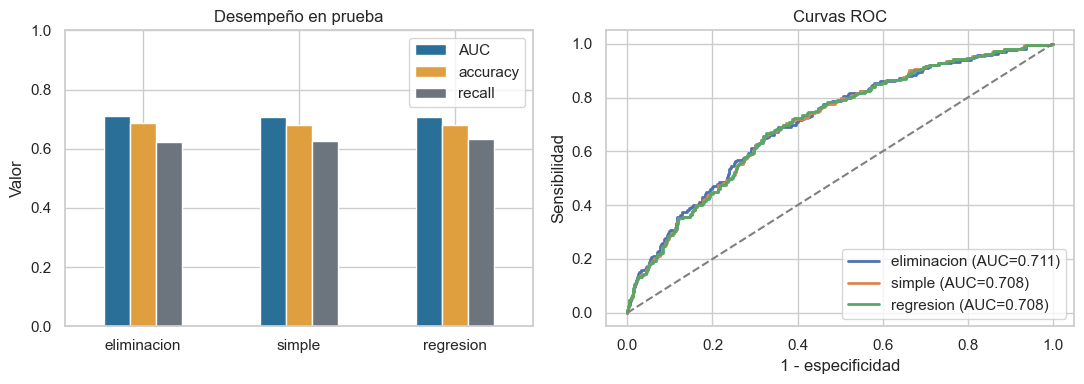

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
metricas.plot(x='estrategia', y=['AUC', 'accuracy', 'recall'], kind='bar', ylim=(0, 1), ax=axes[0],
              color=['#2A6F97', '#E09F3E', '#6C757D'])
axes[0].set(title='Desempeño en prueba', xlabel='', ylabel='Valor')
axes[0].tick_params(axis='x', rotation=0)
for estrategia, y, p in curvas:
    fpr, tpr, _ = roc_curve(y, p)
    auc = metricas.loc[metricas['estrategia'] == estrategia, 'AUC'].iloc[0]
    axes[1].plot(fpr, tpr, lw=2, label=f'{estrategia} (AUC={auc:.3f})')
axes[1].plot([0, 1], [0, 1], '--', color='0.5')
axes[1].set(title='Curvas ROC', xlabel='1 - especificidad', ylabel='Sensibilidad')
axes[1].legend()
fig.tight_layout()
plt.savefig(FIGURAS / 'p4_fig1_metricas_roc_imputacion.png', dpi=180, bbox_inches='tight')
plt.show()

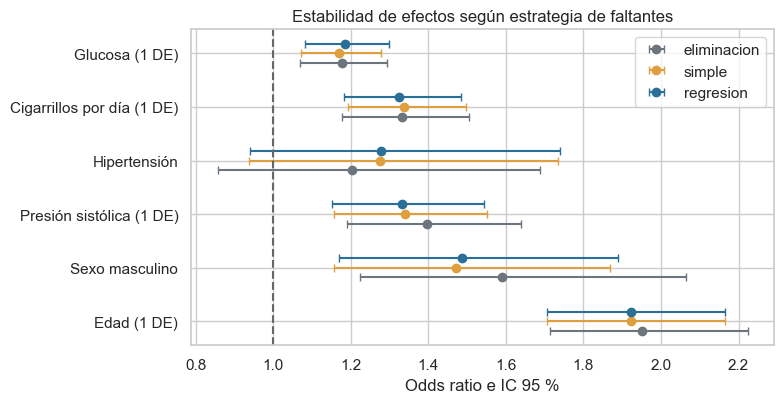

In [45]:
sin_constante = coeficientes.query("variable != 'const'").copy()
variables = sin_constante['variable'].unique().tolist()
estrategias = ['eliminacion', 'simple', 'regresion']
desplazamientos = {'eliminacion': -0.18, 'simple': 0.0, 'regresion': 0.18}
colores = {'eliminacion': '#6C757D', 'simple': '#E09F3E', 'regresion': '#2A6F97'}
fig, ax = plt.subplots(figsize=(8, max(4, 0.7 * len(variables))))
for i, variable in enumerate(variables):
    for estrategia in estrategias:
        fila = sin_constante.query('variable == @variable and estrategia == @estrategia').iloc[0]
        y = i + desplazamientos[estrategia]
        ax.errorbar(fila['odds_ratio'], y,
                    xerr=[[fila['odds_ratio']-fila['IC95_OR_inf']],
                          [fila['IC95_OR_sup']-fila['odds_ratio']]],
                    fmt='o', color=colores[estrategia], capsize=3, label=estrategia if i == 0 else None)
ax.axvline(1, color='0.4', linestyle='--')
etiquetas = [NOMBRES[v].split(' (')[0] + (' (1 DE)' if v in NUMERICAS else '') for v in variables]
ax.set_yticks(range(len(variables)), etiquetas)
ax.set(xlabel='Odds ratio e IC 95 %', title='Estabilidad de efectos según estrategia de faltantes')
ax.legend()
fig.tight_layout()
plt.savefig(FIGURAS / 'p4_fig2_or_imputacion.png', dpi=180, bbox_inches='tight')
plt.show()

## 4.2 Interpretación y recomendación

La estrategia de imputación casi no cambia el desempeño del modelo final. En prueba, el AUC va de 0,708 (simple y regresión) a 0,711 (eliminación) y el recall de 0,624 a 0,632. La comparación de eliminación debe leerse con cuidado: se evalúa sobre 1.111 filas de prueba y no sobre 1.272, así que parte de su diferencia es composición muestral. Simple y regresión sí se evalúan sobre exactamente las mismas filas y sus diferencias son mínimas (un caso detectado más con regresión).

Los cinco efectos significativos (edad, sexo, presión sistólica, cigarrillos y glucosa) mantienen signo y significación al 5 % en las tres estrategias. La hipertensión es no significativa en las tres (p entre 0,118 y 0,284), lo mismo que se observa en el bootstrap de la Parte 3, donde es el único parámetro inestable. Su efecto no depende de cómo se traten los faltantes: es débil una vez que se ajusta por presión sistólica y edad.

La eliminación tiene un costo concreto. Usa 2.547 filas de entrenamiento en vez de 2.968, pierde 87 casos de CHD en total (59 en entrenamiento y 28 en prueba), ensancha los IC de los coeficientes en promedio un 9 % (0,369 frente a 0,340) y sube el OR de sexo de 1,49 a 1,59 y el de sistólica de 1,33 a 1,40. Además supone que los faltantes son MCAR, algo más fuerte que el supuesto MAR de la Parte 1. La imputación simple con mediana comprime la variabilidad de la glucosa, como anticipó la S2, aunque eso no alcanza a mover los OR.

Recomendación: mantener la imputación por regresión, que conserva toda la muestra y las correlaciones validadas en la S2, y reportar la eliminación como análisis de sensibilidad. Las conclusiones del modelo final son robustas a la estrategia de faltantes.

# 5. Cierre

**Checklist de integración S1 → S2 → S3 (template del curso).**

| Requisito | Dónde se cumple |
| --- | --- |
| Faltantes de la S1 usados para decidir la imputación (patrón MAR como supuesto operativo) | Sección 0 y parte 1 |
| Correlaciones estables de la S2 como predictores de la imputación y del modelo 1 | Parte 1 (`PREDICTORES_IMPUTACION`) y parte 2, tabla de la sección 2.2 |
| Outliers de la S1 conservados y probados | Parte 2, sensibilidad al recorte |
| Bootstrap de la S2 aplicado al modelo final (10.000 remuestras, percentil y BCa) | Parte 3 |
| IC bootstrap de coeficientes y odds ratios comparados con Wald | Parte 3, tabla `p3_estabilidad_bootstrap` y forest plot |
| Impacto de la imputación sobre el modelo | Parte 4 |
| Progresión S1 → S2 → S3 explícita | Encabezados de cada parte e informe |

**Conclusiones integradas.**

- La S1 mostró las mayores diferencias en edad, presión sistólica y glucosa, y 13,7 % de filas incompletas. La S2
  validó esas diferencias y las correlaciones que se usaron para imputar. La S3 imputó por regresión dentro del
  entrenamiento porque eliminar costaba 87 casos de CHD.
- El modelo final (edad, sexo, presión sistólica, hipertensión, cigarrillos y glucosa, ponderado) tiene en prueba
  AUC 0,708 (IC bootstrap [0,669; 0,745]) y recall 0,632, frente a 0,062 sin ponderar.
- Cinco efectos son estables en 10.000 remuestras: cada 10 años de edad la odds se multiplica por 2,14, ser
  hombre por 1,49, cada 10 mmHg de sistólica por 1,14, cada 10 cigarrillos diarios por 1,27 y cada 10 mg/dL de
  glucosa por 1,07. La hipertensión es inestable (signo opuesto en 6,0 % de las remuestras).
- Los IC de Wald con EE robustos y los bootstrap coinciden, así que las inferencias de la parte 2 son confiables.
- La estrategia de imputación no cambia ninguna conclusión: en prueba el AUC va de 0,708 a 0,711 y el recall de 0,624
  a 0,632, y los cinco efectos significativos conservan signo y significación en las tres estrategias. La
  eliminación pierde 87 casos, ensancha los IC un 9 % y sube el OR de sexo de 1,49 a 1,59; se mantiene la
  imputación por regresión y la eliminación queda como análisis de sensibilidad.

In [46]:
print(f"Tiempo total de ejecución: {(time.time() - INICIO) / 60:.1f} minutos")

Tiempo total de ejecución: 3.6 minutos
